# AIML Assignment 2 - Feature Engineering

**Question:** To implement techniques of Feature Engineering to transform raw data into informative features. (RBT Level 3, CO 2, 10 Marks)

| | |
|---|---|
| **Student Name** | Tejas Lalit Patil |
| **PRN Number** | 202502040021 |
| **Roll Number** | 370 |
| **Batch** | E1 |
| **Project** | AI-Based System Resource Anomaly Detection and Performance Bottleneck Identification in Kali Linux |
| **Dataset** | Monitoring recording in the schema of the project's agent: 19 system fields every 5 seconds, the busiest processes of every sample and a table of labelled stress runs. **Demonstration recording (generated, fixed seed 42)** - it stands in until the agent's own sessions are recorded |

## Aim
To take the raw monitoring records of a Kali Linux machine and prepare them step by step - cleaning, handling missing values, visualising, encoding the categorical attributes, scaling the numerical attributes, constructing new informative features and selecting the useful ones - so that the final dataset is completely numerical and ready for the anomaly detectors of the project (Isolation Forest, Local Outlier Factor and a percentile rule).

## Dataset description
Every row of `system.csv` is one sample, taken every 5 seconds. The label of a sample comes from `experiments.csv` (`normal`, `cpu`, `memory`, `disk` or `network`, with `moderate` or `heavy` intensity); samples outside every run are unlabelled background. The columns describe

* **When** - `ts` (UTC), `sample_id`, `host_id`
* **CPU and load** - `cpu_percent`, `cpu_count`, `load_average`, `process_count`
* **Memory** - `ram_total`, `ram_used`, `ram_available`, `ram_percent`, `swap_percent`
* **Disk** - `disk_used`, `disk_free`, `disk_percent`, `disk_read_rate`, `disk_write_rate`
* **Network** - `network_sent_rate`, `network_recv_rate`
* **Processes** (`process.csv`) - the busiest processes of every sample: name, CPU, memory, threads, status, I/O rates

Apart from the identifiers and the time stamp, every column of `system.csv` is already numerical. The text columns are in the process table (`process_name`, `status`) and in the run table (`label`, `intensity`), so the encoding steps work there - and that is also where label leakage hides.

**About the data.** The recording used here is a *demonstration recording*: the cell below generates it with a fixed seed, to the schema and the collection protocol of the project's agent (5 sessions of 70 minutes - 30 minutes of ordinary use followed by 8 stress runs of 3 minutes - plus 2 hours of background use), including the faults that a real export has. The numbers in this notebook therefore describe this recording, not a measured laptop. To use the agent's own recording, put `system.csv`, `process.csv` and `experiments.csv` in the working folder before running; nothing else has to change.

### Demonstration recording (data source)
The next cell writes `demo_recording.py`, the generator of the demonstration recording. It is collapsed by default: open it only to see how the recording is made - nothing later in the notebook depends on its details.

In [1]:
%%writefile demo_recording.py
"""Demonstration recording in the schema of the Kali monitoring agent (specification 5.1 to 5.3 and 9).

NOT a measurement. A fixed seed generates 2 hours of ordinary background use and five sessions of
70 minutes (30 min of ordinary use, then eight 3-minute stress runs, each followed by a 2-minute
cooldown), sampled every 5 seconds. It contains the faults of a real export: samples lost in a restart,
null rates after a restart or a counter reset, one void run, rows sent twice, a few corrupted values
and rows that arrive late.
"""

import uuid
import numpy as np
import pandas as pd
from scipy.signal import lfilter

STEP, CPU_COUNT, HOST = 5.0, 8, "kali-laptop-01"
RAM_TOTAL, DISK_TOTAL = 16 * 2**30 - 700 * 2**20, 512e9
BACKGROUND_START = "2026-01-05 07:30"  # two hours of ordinary use before S1
SESSIONS = {
    "S1": ("2026-01-05 10:00", 7, 44),
    "S2": ("2026-01-06 15:30", 11, 47),  # start, CPU %, RAM %
    "S3": ("2026-01-07 11:15", 9, 50),
    "S4": ("2026-01-08 20:00", 13, 45),  # of ordinary use
    "S5": ("2026-01-09 14:00", 10, 48),
}
RUN_ORDER = [
    ("cpu", "moderate"),
    ("cpu", "heavy"),
    ("disk", "moderate"),
    ("disk", "heavy"),
    ("network", "moderate"),
    ("network", "heavy"),
    ("memory", "moderate"),
    ("memory", "heavy"),
]
COMMANDS = {
    "cpu": "stress-ng --cpu 0 --cpu-load 50 --timeout 180s | stress-ng --cpu 0 --timeout 180s",
    "disk": "fio --name=disk --rw=write --bs=1M --size=1g --direct=1 [--rate=20m] --runtime=180",
    "network": "curl -s -o /dev/null $TEST_FILE_URL (repeated for 180 s) [--limit-rate]",
    "memory": "stress-ng --vm 1 --vm-bytes 35% | 65% --vm-keep --timeout 180s",
}

# Ordinary processes: name, mean CPU %, resident MB, threads, I/O bytes/s, root-owned (I/O denied)
BACKGROUND = [
    ("firefox-esr", 4.0, 1250, 120, 4e5, False),
    ("Isolated Web Co", 2.5, 520, 36, 2e5, False),
    ("Web Content", 2.0, 430, 31, 1.5e5, False),
    ("WebExtensions", 0.6, 210, 20, 4e4, False),
    ("Xorg", 1.8, 240, 9, 1e4, True),
    ("gnome-shell", 2.2, 430, 22, 2e4, False),
    ("gnome-terminal-", 0.5, 95, 5, 1e4, False),
    ("code", 3.0, 780, 44, 3e5, False),
    ("code ", 1.2, 340, 18, 1e5, False),
    ("python3", 1.5, 360, 7, 2e5, False),
    ("java", 1.2, 640, 52, 5e4, False),
    ("ruby", 0.8, 520, 5, 3e4, False),
    ("wireshark", 0.8, 210, 14, 2e4, False),
    ("systemd", 0.1, 28, 1, 1e3, True),
    ("systemd-journal", 0.2, 120, 1, 3e5, True),
    ("systemd-logind", 0.05, 11, 1, 1e3, True),
    ("NetworkManager", 0.2, 52, 4, 1e3, True),
    ("dbus-daemon", 0.1, 8, 1, 1e3, False),
    ("kworker/u16:3-events_unbound", 0.6, 0, 1, 1e5, True),
    ("kworker/2:1H-kblockd", 0.3, 0, 1, 2e5, True),
    ("kworker/0:2-events", 0.3, 0, 1, 5e4, True),
    ("ksoftirqd/3", 0.2, 0, 1, 0, True),
    ("rcu_preempt", 0.2, 0, 1, 0, True),
    ("irq/136-iwlwifi", 0.3, 0, 1, 0, True),
    ("sysmon-agent", 0.4, 58, 3, 1e4, False),
    ("postgres", 0.5, 160, 6, 5e4, False),
    ("tmux: server", 0.1, 12, 1, 1e3, False),
    ("bash", 0.05, 8, 1, 1e3, False),
    ("chromium", 1.5, 690, 40, 1e5, False),
    ("nmap", 0.1, 38, 1, 1e3, False),
    ("snapd", 0.1, 90, 12, 2e3, True),
    ("cron", 0.02, 4, 1, 1e3, True),
]
BURSTY = {"nmap": 60.0, "wireshark": 25.0, "ruby": 30.0, "python3": 40.0, "java": 25.0}


def new_id(rng):
    return str(uuid.UUID(bytes=rng.bytes(16), version=4))


def ar1(n, phi, sigma, rng):
    """Noise in which every value remembers the previous one."""
    return lfilter([1.0], [1.0, -phi], rng.normal(0, sigma, n))


def bursts(n, rate, median, spread, tau, rng):
    """Short bursts of ordinary activity (page loads, compiles): random starts and sizes, fast decay."""
    pulse = np.where(rng.random(n) < rate, median * np.exp(rng.normal(0, spread, n)), 0.0)
    return np.convolve(pulse, np.exp(-np.arange(0, 40) / tau))[:n]


def ordinary_episodes(n, count, rng):
    """Heavy but NORMAL activity: compile, download, file copy, many browser tabs (30 to 120 s each)."""
    add = {k: np.zeros(n) for k in ("cpu", "ram", "read", "write", "recv", "sent", "procs")}
    for _ in range(count):
        kind, length = rng.choice(["compile", "download", "copy", "browser"]), int(rng.integers(6, 25))
        first = int(rng.integers(0, max(n - length, 1)))
        part = slice(first, first + length)
        shape = np.minimum(1.0, np.minimum(np.arange(1, length + 1), np.arange(length, 0, -1)) / 2.0)
        if kind == "compile":
            add["cpu"][part] += rng.uniform(45, 65) * shape
            add["write"][part] += rng.uniform(2e6, 6e6) * shape
            add["read"][part] += 2e6 * shape
            add["ram"][part] += rng.uniform(2, 4) * shape
            add["procs"][part] += rng.integers(10, 20) * shape
        elif kind == "download":
            add["recv"][part] += rng.uniform(2e6, 9e6) * shape * (1 + rng.normal(0, 0.1, length))
            add["sent"][part] += 5e4 * shape
            add["cpu"][part] += 3 * shape
        elif kind == "copy":
            add["write"][part] += rng.uniform(40e6, 150e6) * shape * (1 + rng.normal(0, 0.1, length))
            add["read"][part] += rng.uniform(40e6, 130e6) * shape
            add["cpu"][part] += 6 * shape
        else:
            add["ram"][part] += rng.uniform(8, 14) * shape
            add["cpu"][part] += 8 * shape
            add["procs"][part] += 6 * shape
    return add


def simulate_block(start, minutes, protocol, cpu_base, ram_base, rng):
    """One block of samples. Returns the system rows, the runs and the state of every sample."""
    n = int(minutes * 60 / STEP)
    t0 = pd.Timestamp(start, tz="UTC")
    # Samples fall half a step after the grid, so that no sample sits exactly on a run boundary
    ts = t0 + pd.to_timedelta((np.arange(n) + 0.5) * STEP + rng.normal(0, 0.02, n).round(3), unit="s")
    label = np.array(["background"] * n, dtype=object)
    intensity, since = np.array([""] * n, dtype=object), np.zeros(n)
    runs, t = [], t0
    if protocol:
        plan = [("normal", "", 30)]
        for lab, inten in RUN_ORDER:
            plan += [(lab, inten, 3), ("cooldown", "", 2)]
        for lab, inten, length in plan:
            command = (
                "ordinary use" if lab == "normal" else ("" if lab == "cooldown" else COMMANDS[lab])
            )
            runs.append(
                dict(
                    label=lab,
                    intensity=inten,
                    started_at=t,
                    command=command,
                    ended_at=t + pd.Timedelta(minutes=length),
                )
            )
            t += pd.Timedelta(minutes=length)
        for r in runs:
            m = (ts >= r["started_at"]) & (ts < r["ended_at"])
            label[m], intensity[m] = r["label"], r["intensity"]
            since[m] = (ts[m] - r["started_at"]).total_seconds()
    heavy = intensity == "heavy"
    ramp = np.clip(since / 10.0, 0.25, 1.0)  # the first samples of a run are only partly loaded

    # ---- ordinary use, with a few heavy but normal episodes
    ordinary = (label == "normal") | (label == "background")
    ep = ordinary_episodes(n, 3 if protocol else int(minutes / 15), rng)
    cpu = cpu_base + ar1(n, 0.85, 1.6, rng) + bursts(n, 0.03, 14, 0.5, 3.0, rng)
    ram = (
        ram_base
        + np.clip(np.cumsum(rng.normal(0, 0.06, n)), -3, 3)
        + bursts(n, 0.01, 2.5, 0.4, 12, rng)
    )
    swap = 2.0 + np.arange(n) * 0.0005 + np.abs(ar1(n, 0.95, 0.03, rng))
    disk_read = np.exp(rng.normal(np.log(4e4), 1.5, n)) + bursts(n, 0.02, 6e6, 0.8, 1.5, rng)
    disk_write = np.exp(rng.normal(np.log(1.5e5), 1.4, n)) + bursts(n, 0.02, 9e6, 0.9, 1.5, rng)
    net_recv = np.exp(rng.normal(np.log(2.5e4), 1.5, n)) + bursts(n, 0.03, 1.2e6, 0.9, 2.0, rng)
    net_sent = np.exp(rng.normal(np.log(9e3), 1.3, n)) + bursts(n, 0.03, 1.5e5, 0.8, 2.0, rng)
    procs = 300 + np.round(ar1(n, 0.97, 0.5, rng))
    cpu, ram, procs = (
        cpu + ep["cpu"] * ordinary,
        ram + ep["ram"] * ordinary,
        procs + ep["procs"] * ordinary,
    )
    disk_read, disk_write = disk_read + ep["read"] * ordinary, disk_write + ep["write"] * ordinary
    net_recv, net_sent = net_recv + ep["recv"] * ordinary, net_sent + ep["sent"] * ordinary
    extra_load, disk_extra = np.zeros(n), np.zeros(n)

    # ---- stress, on top of ordinary use
    m, k = label == "cpu", (label == "cpu").sum()
    cpu[m] = (
        np.where(heavy[m], 98.5 + rng.normal(0, 0.8, k), 51 + rng.normal(0, 2.4, k)) * ramp[m]
        + cpu[m] * 0.02
    )
    procs[m] += CPU_COUNT + 1
    m, k = label == "memory", (label == "memory").sum()
    ram[m] = np.where(
        heavy[m], 95.5 + rng.normal(0, 0.6, k), ram[m] + 35 * ramp[m] + rng.normal(0, 0.5, k)
    )
    cpu[m] += np.where(heavy[m], 12, 5) * ramp[m]
    disk_read[m] += np.where(heavy[m], rng.uniform(15e6, 45e6, k), 0)
    disk_write[m] += np.where(heavy[m], rng.uniform(25e6, 70e6, k), 0)
    procs[m] += 2
    m, k = label == "disk", (label == "disk").sum()
    disk_write[m] = (
        np.where(heavy[m], 550e6 * (1 + rng.normal(0, 0.12, k)), 20e6 * (1 + rng.normal(0, 0.04, k)))
        * ramp[m]
        + disk_write[m] * 0.05
    )
    disk_read[m] += 3e5
    cpu[m] += np.where(heavy[m], 9, 4) * ramp[m]
    extra_load[m] += np.where(heavy[m], 1.5, 0.3)
    disk_extra[m] = 2**30
    procs[m] += 1
    m, k = label == "network", (label == "network").sum()
    net_recv[m] = (
        np.where(heavy[m], 11.5e6 * (1 + rng.normal(0, 0.05, k)), 6.0e6 * (1 + rng.normal(0, 0.08, k)))
        * ramp[m]
        + net_recv[m] * 0.05
    )
    net_sent[m] += np.where(heavy[m], 4.5e5, 2.5e5) * ramp[m]
    cpu[m] += np.where(heavy[m], 6, 3) * ramp[m]
    procs[m] += rng.integers(0, 2, k)

    # swap stays occupied after memory pressure: it grows in heavy memory runs and drains very slowly
    swap_state, swap_out = swap[0], np.empty(n)
    for i in range(n):
        swap_state += (0.45 if (label[i] == "memory" and heavy[i]) else -0.002) + rng.normal(0, 0.004)
        swap_state = max(swap_state, swap[i])
        swap_out[i] = swap_state
    cpu, ram = np.clip(cpu, 0.4, 100.0), np.clip(ram, 5, 98)
    busy = cpu / 100 * CPU_COUNT + extra_load + np.where(heavy & (label == "memory"), 1.0, 0.0)
    load, level, a = np.empty(n), busy[0], 1 - np.exp(-STEP / 60)  # 1-minute load average
    for i in range(n):
        level += a * (busy[i] - level) + rng.normal(0, 0.02)
        load[i] = max(level, 0.0)
    ram_available = RAM_TOTAL * (1 - ram / 100)
    ram_used = (RAM_TOTAL - ram_available) * rng.uniform(0.9, 0.96, n)  # "used" leaves out cached pages
    disk_used = 297.9e9 + np.arange(n) * 6e5 + disk_extra
    system = pd.DataFrame(
        dict(
            sample_id=[new_id(rng) for _ in range(n)],
            host_id=HOST,
            ts=ts,
            cpu_percent=cpu.round(1),
            cpu_count=CPU_COUNT,
            ram_total=RAM_TOTAL,
            ram_used=ram_used.astype("int64"),
            ram_available=ram_available.astype("int64"),
            ram_percent=ram.round(1),
            swap_percent=swap_out.round(1),
            disk_used=disk_used.astype("int64"),
            disk_free=(DISK_TOTAL - disk_used).astype("int64"),
            disk_percent=(disk_used / DISK_TOTAL * 100).round(1),
            disk_read_rate=disk_read.round(1),
            disk_write_rate=disk_write.round(1),
            network_sent_rate=net_sent.round(1),
            network_recv_rate=net_recv.round(1),
            load_average=load.round(2),
            process_count=procs.astype(int),
        )
    )
    return system, runs, (label, intensity, ramp)


def process_rows(system, state, rng):
    """The busiest processes of every sample: top 5 by CPU, top 5 by memory, top 3 by disk I/O."""
    label, intensity, ramp = state
    n, m = len(system), len(BACKGROUND)
    names = [b[0] for b in BACKGROUND]
    cpu_mean, mem_mb, threads = (np.array([b[k] for b in BACKGROUND], dtype=float) for k in (1, 2, 3))
    io_scale, denied = np.array([b[4] for b in BACKGROUND], dtype=float), np.array(
        [b[5] for b in BACKGROUND]
    )
    pids = rng.choice(np.arange(300, 4000), size=m, replace=False)
    cpu = cpu_mean * np.exp(rng.normal(0, 0.9, (n, m)))
    for name, peak in BURSTY.items():
        cpu[:, names.index(name)] += np.where(rng.random(n) < 0.01, peak * rng.uniform(0.3, 1.0, n), 0)
    mem = mem_mb * (1 + np.cumsum(rng.normal(0, 0.002, (n, m)), axis=0).clip(-0.15, 0.15))
    io = io_scale * np.exp(rng.normal(0, 1.5, (n, m)))
    io[:, denied] = np.nan  # the OS denies the I/O counters of root processes
    rows, total_mb = [], RAM_TOTAL / 2**20
    for i in range(n):
        entries = [
            (
                pids[j],
                names[j],
                cpu[i, j],
                mem[i, j],
                threads[j],
                io[i, j],
                np.nan if denied[j] else io[i, j] * rng.uniform(0.3, 3),
            )
            for j in range(m)
        ]
        lab, heavy = label[i], intensity[i] == "heavy"
        if lab == "cpu":
            for k in range(CPU_COUNT):
                entries.append(
                    (
                        9100 + k,
                        "stress-ng-cpu",
                        (98.0 if heavy else 50.0) * ramp[i] + rng.normal(0, 1.5),
                        12.0,
                        1,
                        0.0,
                        0.0,
                    )
                )
        elif lab == "memory":
            entries.append(
                (
                    9200,
                    "stress-ng-vm",
                    97.0 + rng.normal(0, 2),
                    total_mb * (0.65 if heavy else 0.35) * ramp[i],
                    1,
                    0.0,
                    0.0,
                )
            )
        elif lab == "disk":
            entries.append(
                (
                    9300,
                    "fio",
                    (26.0 if heavy else 12.0) + rng.normal(0, 2),
                    25.0,
                    2,
                    2e5,
                    system["disk_write_rate"].iat[i],
                )
            )
        elif lab == "network":
            entries.append(
                (
                    9400 + int(rng.integers(0, 50)),
                    "curl",
                    (16.0 if heavy else 9.0) + rng.normal(0, 2),
                    18.0,
                    1,
                    0.0,
                    0.0,
                )
            )
        cpu_i, mem_i, read_i, write_i = (
            np.array([e[k] for e in entries], dtype=float) for k in (2, 3, 5, 6)
        )
        io_total = np.nan_to_num(read_i) + np.nan_to_num(write_i)
        chosen = (
            set(np.argsort(-cpu_i)[:5]) | set(np.argsort(-mem_i)[:5]) | set(np.argsort(-io_total)[:3])
        )
        for k in sorted(chosen):
            pid, name, c, mb, th, rd, wr = entries[k]
            running = c > 20 or name.startswith(("stress", "fio", "curl"))
            status = (
                ("running" if rng.random() < 0.8 else "sleeping")
                if running
                else ("idle" if name.startswith(("kworker", "ksoftirqd", "rcu", "irq")) else "sleeping")
            )
            if name == "fio" and rng.random() < 0.5:
                status = "disk-sleep"
            if rng.random() < 0.0007:
                status = "zombie"
            rows.append(
                (
                    system["sample_id"].iat[i],
                    HOST,
                    system["ts"].iat[i],
                    int(pid),
                    name,
                    round(float(c), 1),
                    round(float(mb) / total_mb * 100, 2),
                    round(float(mb), 1),
                    float(th),
                    status,
                    rd,
                    wr,
                )
            )
    return pd.DataFrame(
        rows,
        columns=[
            "sample_id",
            "host_id",
            "ts",
            "pid",
            "process_name",
            "cpu_percent",
            "memory_percent",
            "memory_mb",
            "num_threads",
            "status",
            "io_read_rate",
            "io_write_rate",
        ],
    )


def make_demo_recording(seed=42):
    """Return (system, process, experiments) as the exports of the agent would look, faults included."""
    rng = np.random.default_rng(seed)
    rate = ["disk_read_rate", "disk_write_rate", "network_sent_rate", "network_recv_rate"]
    blocks, runs = [], []
    s, _, state = simulate_block(BACKGROUND_START, 120, False, 8, 45, rng)
    blocks.append((s, process_rows(s, state, rng)))
    s.loc[0, rate] = np.nan  # first sample after the agent starts
    for sid, (start, cpu_base, ram_base) in SESSIONS.items():
        s, r, state = simulate_block(start, 70, True, cpu_base, ram_base, rng)
        p = process_rows(s, state, rng)
        t0 = pd.Timestamp(start, tz="UTC")
        lost = pd.Series(False, index=s.index)
        if sid == "S2":  # agent restarted 12 minutes in
            lost.iloc[144:146] = True
            s.loc[146, rate] = np.nan
        if sid == "S3":  # agent stopped 40 s inside a run: void run
            run = next(x for x in r if x["label"] == "network" and x["intensity"] == "heavy")
            gap = s["ts"].between(
                run["started_at"] + pd.Timedelta(seconds=70),
                run["started_at"] + pd.Timedelta(seconds=110),
            )
            lost |= gap
            s.loc[gap[gap].index[-1] + 1, rate] = np.nan
            reset = s.index[s["ts"] >= t0 + pd.Timedelta(minutes=21)][
                0
            ]  # Wi-Fi reconnect: counters reset
            s.loc[reset, ["network_sent_rate", "network_recv_rate"]] = np.nan
        if sid == "S5":
            reset = s.index[s["ts"] >= t0 + pd.Timedelta(minutes=8)][0]
            s.loc[reset, ["network_sent_rate", "network_recv_rate"]] = np.nan
        p = p[~p["sample_id"].isin(s.loc[lost, "sample_id"])]
        s = s[~lost]
        for x in r:
            x["session_id"] = sid
        blocks.append((s, p)), runs.extend(r)
    system = pd.concat([b[0] for b in blocks], ignore_index=True)
    process = pd.concat([b[1] for b in blocks], ignore_index=True)
    experiments = pd.DataFrame(runs)[
        ["session_id", "label", "intensity", "started_at", "ended_at", "command"]
    ]
    experiments.insert(0, "run_id", [new_id(rng) for _ in range(len(experiments))])
    process.loc[rng.random(len(process)) < 0.004, ["status", "num_threads"]] = (
        np.nan
    )  # process exited early

    # faults of the export: rows resent after a lost response, a clock step, corrupted values, late rows
    s3 = pd.Timestamp(SESSIONS["S3"][0], tz="UTC")
    window = system[system["ts"].between(s3 + pd.Timedelta(minutes=5), s3 + pd.Timedelta(minutes=6))]
    clock_step = window.sample(1, random_state=2).copy()
    clock_step["sample_id"] = new_id(rng)
    corrupt = system.dropna(subset=rate).sample(3, random_state=3).index  # three corrupted values
    system.loc[corrupt[:2], "cpu_percent"] = [187.3, 134.0]
    system.loc[corrupt[2], "disk_write_rate"] = -5.0
    system = pd.concat(
        [system, system.loc[window.sample(5, random_state=1).index], clock_step], ignore_index=True
    )
    s4 = pd.Timestamp(SESSIONS["S4"][0], tz="UTC")  # buffered rows arrive after a 5-minute outage
    late = system["ts"].between(s4 + pd.Timedelta(minutes=14), s4 + pd.Timedelta(minutes=19))
    system = pd.concat([system[~late], system[late].sample(frac=1, random_state=5)], ignore_index=True)

    iso = lambda col: col.dt.strftime("%Y-%m-%dT%H:%M:%S.%f").str[:-3] + "Z"
    system["ts"], process["ts"] = iso(system["ts"]), iso(process["ts"])
    for c in ("started_at", "ended_at"):
        experiments[c] = iso(experiments[c])
    return system, process, experiments

Writing demo_recording.py


## Step 1 - Import the libraries and load the data

In [2]:
import os, re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 112)
pd.set_option("display.max_colwidth", 60)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# One fixed colour per label for the whole notebook (colour follows the label, never its rank)
LABELS = ["normal", "cpu", "memory", "disk", "network"]
LABEL_COLORS = {
    "normal": "#2a78d6",
    "cpu": "#eb6834",
    "memory": "#1baf7a",
    "disk": "#eda100",
    "network": "#e87ba4",
    "background": "#9aa0a6",
}
RATE_FIELDS = ["disk_read_rate", "disk_write_rate", "network_sent_rate", "network_recv_rate"]
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save(name):
    """Save the current figure to figures/<name>.png and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")
    plt.show()


print(
    "Python",
    sys.version.split()[0],
    "| pandas",
    pd.__version__,
    "| NumPy",
    np.__version__,
    "| scikit-learn",
    sklearn.__version__,
)

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | scikit-learn 1.9.1


In [3]:
# To use real data, put system.csv, process.csv and experiments.csv (agent exports) in this folder.
# Otherwise the demonstration recording is generated once, with a fixed seed.
FILES = ["system.csv", "process.csv", "experiments.csv"]
if not all(os.path.exists(f) for f in FILES):
    from demo_recording import make_demo_recording

    for name, table in zip(FILES, make_demo_recording(seed=RANDOM_STATE)):
        table.to_csv(name, index=False)
    print("Demonstration recording written to:", ", ".join(FILES))

system = pd.read_csv("system.csv")
process = pd.read_csv("process.csv")
experiments = pd.read_csv("experiments.csv")
print("system.csv      (rows, columns):", system.shape)
print("process.csv     (rows, columns):", process.shape)
print("experiments.csv (rows, columns):", experiments.shape)
system.head()

Demonstration recording written to: system.csv, process.csv, experiments.csv
system.csv      (rows, columns): (5636, 19)
process.csv     (rows, columns): (49976, 12)
experiments.csv (rows, columns): (85, 7)


,sample_id,host_id,ts,cpu_percent,cpu_count,ram_total,ram_used,ram_available,ram_percent,swap_percent,disk_used,disk_free,disk_percent,disk_read_rate,disk_write_rate,network_sent_rate,network_recv_rate,load_average,process_count
0,2b9d093d-1e9a-45c7-bad0-78344715f94d,kali-laptop-01,2026-01-05T07:30:02.506Z,8.9,8,16445865984,6833318983,9064750813,44.9,2.0,297900000000,214100000000,58.2,NaN,NaN,NaN,NaN,0.74,300
1,e6781269-2512-4654-87fb-4cbd124761e8,kali-laptop-01,2026-01-05T07:30:07.479Z,9.4,8,16445865984,6907918581,9055609772,44.9,2.1,297900600000,214099400000,58.2,124845.1,542583.7,3576.4,16110.3,0.74,299
2,9196d589-6a77-4b93-a5a8-59bb86507d66,kali-laptop-01,2026-01-05T07:30:12.515Z,6.7,8,16445865984,6644631105,9063214465,44.9,2.1,297901200000,214098800000,58.2,37565.7,376045.8,4585.0,5230.3,0.74,299
3,5d615b74-fcbf-47f3-8d83-9d621e1fea43,kali-laptop-01,2026-01-05T07:30:17.519Z,5.7,8,16445865984,6800932092,9063556437,44.9,2.1,297901800000,214098200000,58.2,78562.9,172005.4,11927.3,8011.5,0.73,300
4,50fd6505-9193-4f05-93a7-cfc47fa41a3b,kali-laptop-01,2026-01-05T07:30:22.461Z,5.1,8,16445865984,6952935883,9077634362,44.8,2.1,297902400000,214097600000,58.2,9102.1,26951.8,2386.5,17416.7,0.69,300


In [4]:
system.tail()

,sample_id,host_id,ts,cpu_percent,cpu_count,ram_total,ram_used,ram_available,ram_percent,swap_percent,disk_used,disk_free,disk_percent,disk_read_rate,disk_write_rate,network_sent_rate,network_recv_rate,load_average,process_count
5631,ec86fb6b-9a51-4716-885b-0929828f6de1,kali-laptop-01,2026-01-08T20:18:32.490Z,14.0,8,16445865984,6853603831,9068092199,44.9,2.2,298033200000,213966800000,58.2,10587.7,100440.1,54302.1,6369477.9,1.02,303
5632,03beb5db-9d4b-41d3-b35b-fa51774dc508,kali-laptop-01,2026-01-08T20:17:12.497Z,12.6,8,16445865984,6802008691,9049636074,45.0,2.2,298023600000,213976400000,58.2,113228.0,303459.1,79328.9,99843.8,1.09,301
5633,5062bf38-8dee-4df4-aabd-df586d71a5bd,kali-laptop-01,2026-01-08T20:17:57.491Z,16.1,8,16445865984,6798970706,9090995847,44.7,2.2,298029000000,213971000000,58.2,20001.0,55154.5,48157.9,3284126.4,1.02,302
5634,3892a147-1132-4d28-b904-93126cafcbdd,kali-laptop-01,2026-01-08T20:15:12.516Z,16.4,8,16445865984,6737184873,9109811847,44.6,2.2,298009200000,213990800000,58.2,738219.4,18893.9,87028.2,3461.4,1.46,301
5635,0ae86af7-5fb9-47f5-aa0d-799511c72a55,kali-laptop-01,2026-01-08T20:16:57.527Z,12.5,8,16445865984,6663834562,9059751881,44.9,2.2,298021800000,213978200000,58.2,135660.6,387064.8,153019.2,464602.7,1.18,303


In [5]:
system.info()

<class 'pandas.DataFrame'>
RangeIndex: 5636 entries, 0 to 5635
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sample_id          5636 non-null   str    
 1   host_id            5636 non-null   str    
 2   ts                 5636 non-null   str    
 3   cpu_percent        5636 non-null   float64
 4   cpu_count          5636 non-null   int64  
 5   ram_total          5636 non-null   int64  
 6   ram_used           5636 non-null   int64  
 7   ram_available      5636 non-null   int64  
 8   ram_percent        5636 non-null   float64
 9   swap_percent       5636 non-null   float64
 10  disk_used          5636 non-null   int64  
 11  disk_free          5636 non-null   int64  
 12  disk_percent       5636 non-null   float64
 13  disk_read_rate     5633 non-null   float64
 14  disk_write_rate    5633 non-null   float64
 15  network_sent_rate  5631 non-null   float64
 16  network_recv_rate  5631 non-null   

In [6]:
# Statistics of the numerical columns of system.csv (4 significant digits keep the byte counts readable)
numeric_cols = [
    "cpu_percent",
    "cpu_count",
    "ram_total",
    "ram_used",
    "ram_available",
    "ram_percent",
    "swap_percent",
    "disk_used",
    "disk_free",
    "disk_percent",
    "load_average",
    "process_count",
]
summary = system[numeric_cols + RATE_FIELDS].agg(["count", "mean", "std", "min", "median", "max"]).T
with pd.option_context("display.float_format", "{:.4g}".format):
    display(summary)

,count,mean,std,min,median,max
cpu_percent,5636,16.8,18.18,0.4,11.6,187.3
cpu_count,5636,8,0,8,8,8
ram_total,5636,1.645e+10,0,1.645e+10,1.645e+10,1.645e+10
ram_used,5636,7.611e+09,1.602e+09,6.36e+09,7.234e+09,1.525e+10
ram_available,5636,8.261e+09,1.717e+09,4.441e+08,8.664e+09,9.421e+09
ram_percent,5636,49.77,10.44,42.7,47.3,97.3
swap_percent,5636,2.997,2.88,2,2.4,18.8
disk_used,5636,2.983e+11,3.309e+08,2.979e+11,2.982e+11,2.993e+11
disk_free,5636,2.137e+11,3.309e+08,2.127e+11,2.138e+11,2.141e+11
disk_percent,5636,58.26,0.07874,58.2,58.2,58.5


In [7]:
# Statistics of the text columns: the process table and the table of labelled runs
display(process[["process_name", "status"]].describe().T)
display(experiments[["session_id", "label", "intensity"]].describe().T)

,count,unique,top,freq
process_name,49976,32,firefox-esr,5630
status,49775,5,sleeping,46263


,count,unique,top,freq
session_id,85,5,S1,17
label,85,6,cooldown,40
intensity,40,2,moderate,20


In [8]:
# Number of unique values in every text column (cardinality) - decides the encoding technique in Step 6
cardinality = pd.Series(
    {
        "process.process_name": process["process_name"].nunique(),
        "process.status": process["status"].nunique(),
        "experiments.label": experiments["label"].nunique(),
        "experiments.intensity": experiments["intensity"].nunique(),
        "experiments.session_id": experiments["session_id"].nunique(),
    },
    name="unique values",
)
print(cardinality.to_string())

process.process_name      32
process.status             5
experiments.label          6
experiments.intensity      2
experiments.session_id     5


## Step 2 - Clean the raw values

Real exports are messy. The checks follow the preprocessing rules of the project (specification 10.2, operations 1, 2, 4 and 10) and a text clean-up of the process table:

* the rows are not in time order - rows that were buffered during an outage arrive late,
* a retry after a lost response sends a sample twice, and a clock step can give two samples the same time,
* corrupted rows break the physical ranges (CPU above 100 %, a negative rate),
* process names carry trailing spaces (`'code '`) and kernel threads carry a CPU number (`kworker/2:1H-kblockd`), so one thing would be counted as several categories,
* `intensity` is empty for normal and cooldown runs,
* the label of a sample is not stored - it comes from the run whose interval contains the time stamp.

In [9]:
# Operation 1 - parse ts as UTC and put the rows in time order
system["ts"] = pd.to_datetime(system["ts"], utc=True).astype("datetime64[ns, UTC]")
late = system["ts"].diff() < pd.Timedelta(0)
print("Rows that arrived late (time earlier than the row before):", int(late.sum()))
system = system.sort_values(["host_id", "ts"], kind="mergesort").reset_index(drop=True)
print("After sorting:", int((system["ts"].diff() < pd.Timedelta(0)).sum()))
print(
    "Time span:",
    system["ts"].min().strftime("%Y-%m-%d %H:%M"),
    "to",
    system["ts"].max().strftime("%Y-%m-%d %H:%M"),
    "UTC",
)

Rows that arrived late (time earlier than the row before): 30
After sorting: 0
Time span: 2026-01-05 07:30 to 2026-01-09 15:09 UTC


In [10]:
# Operation 2 - drop repeats of sample_id and of (host_id, ts)
rows_before = len(system)
repeated_id = int(system.duplicated("sample_id").sum())
system = system.drop_duplicates("sample_id")
repeated_ts = int(system.duplicated(["host_id", "ts"]).sum())
system = system.drop_duplicates(["host_id", "ts"]).reset_index(drop=True)
print(f"repeated sample_id: {repeated_id} | same host and time with a new sample_id: {repeated_ts}")
print(f"rows: {rows_before} -> {len(system)}")

repeated sample_id: 5 | same host and time with a new sample_id: 1
rows: 5636 -> 5630


In [11]:
# Operation 4 - ranges: percentages within 0-100, rates and load not negative
PERCENT_COLS = ["cpu_percent", "ram_percent", "swap_percent", "disk_percent"]
NON_NEGATIVE = RATE_FIELDS + ["load_average"]
out_of_range = pd.Series(False, index=system.index)
for col in PERCENT_COLS:
    out_of_range |= (system[col] < 0) | (system[col] > 100)
for col in NON_NEGATIVE:
    out_of_range |= system[col] < 0
print("Rows that break a range:", int(out_of_range.sum()))
display(system.loc[out_of_range, ["ts", "cpu_percent", "disk_write_rate", "load_average"]])
system = system[~out_of_range].reset_index(drop=True)
print("rows left:", len(system))

Rows that break a range: 3


,ts,cpu_percent,disk_write_rate,load_average
1225,2026-01-05 09:12:07.510000+00:00,134.0,197175.6,0.89
2333,2026-01-06 15:34:27.489000+00:00,187.3,3402.0,1.19
5010,2026-01-09 14:18:22.505000+00:00,9.6,-5.0,0.83


rows left: 5627


In [12]:


# Repair the process names: strip spaces and drop the CPU number of kernel threads
def clean_name(name):
    name = str(name).strip()
    return re.sub(r"^(kworker|ksoftirqd|irq)[/_].*$", r"\1", name)


examples = ["code ", "kworker/2:1H-kblockd", "kworker/0:2-events", "ksoftirqd/3", "irq/136-iwlwifi"]
print(
    pd.DataFrame({"raw": examples, "clean": [clean_name(n) for n in examples]}).to_string(index=False)
)
names_before = process["process_name"].nunique()
process["process_name"] = process["process_name"].map(clean_name)
print(f"\nDistinct process names: {names_before} -> {process['process_name'].nunique()}")

                 raw     clean
               code       code
kworker/2:1H-kblockd   kworker
  kworker/0:2-events   kworker
         ksoftirqd/3 ksoftirqd
     irq/136-iwlwifi       irq

Distinct process names: 32 -> 29


In [13]:
# Operation 10 - a sample takes the label of the run whose interval contains its time stamp
runs = experiments.copy()
for col in ("started_at", "ended_at"):
    runs[col] = pd.to_datetime(runs[col], utc=True).astype("datetime64[ns, UTC]")
runs["intensity"] = runs["intensity"].fillna("none")  # normal and cooldown runs have no intensity
runs = runs.sort_values("started_at").reset_index(drop=True)

sysd = pd.merge_asof(
    system.sort_values("ts"),
    runs[["run_id", "session_id", "label", "intensity", "started_at", "ended_at"]],
    left_on="ts",
    right_on="started_at",
    direction="backward",
)
outside = ~(sysd["ts"] < sysd["ended_at"])  # not inside any run: unlabelled background
for col, fill in [
    ("run_id", "-"),
    ("session_id", "BG"),
    ("label", "background"),
    ("intensity", "none"),
]:
    sysd.loc[outside, col] = fill
sysd.loc[outside, ["started_at", "ended_at"]] = pd.NaT

# Rows within 30 s of the start or end of a run are trimmed: the label is ambiguous there
since_start = (sysd["ts"] - sysd["started_at"]).dt.total_seconds()
until_end = (sysd["ended_at"] - sysd["ts"]).dt.total_seconds()
sysd["trimmed"] = ((since_start < 30) | (until_end <= 30)) & ~outside

# A stress run is void if fewer than 34 of its 36 samples were stored
runs["samples"] = runs["run_id"].map(sysd.groupby("run_id").size()).fillna(0).astype(int)
runs["void"] = runs["label"].isin(["cpu", "memory", "disk", "network"]) & (runs["samples"] < 34)
print("Void runs (the agent stopped inside the run):")
display(runs.loc[runs["void"], ["session_id", "label", "intensity", "samples"]])
sysd["void"] = sysd["run_id"].isin(runs.loc[runs["void"], "run_id"])
sysd["scored"] = sysd["label"].isin(LABELS) & ~sysd["trimmed"] & ~sysd["void"]

S = sysd[sysd["scored"]]
print("Rows used for scoring (labelled, trimmed, void runs removed):", len(S), "of", len(sysd))
table = pd.crosstab(S["session_id"], S["label"])[LABELS]
print(table.assign(total=table.sum(axis=1)).to_string())

Void runs (the agent stopped inside the run):


,session_id,label,intensity,samples
45,S3,network,heavy,28


Rows used for scoring (labelled, trimmed, void runs removed): 2672 of 5627
label       normal  cpu  memory  disk  network  total
session_id                                           
S1             348   48      48    48       48    540
S2             345   48      48    48       48    537
S3             348   48      48    48       24    516
S4             348   48      48    48       48    540
S5             347   48      48    48       48    539


**Observations:** Sorting by time repaired the 30 rows that had arrived late, and removing repeats took the table from 5636 to 5630 rows (5 resent samples and 1 extra row with the same host and time). The range check found three impossible values - CPU readings of 134.0 % and 187.3 %, and a disk write rate of -5.0 bytes per second - and dropped them, leaving 5627 rows. Cleaning the process names reduced 32 distinct names to 29: `'code '` and `code` became one name, and the numbered kernel threads (`kworker/2:1H-kblockd`, `ksoftirqd/3`, `irq/136-iwlwifi`) were folded into `kworker`, `ksoftirqd` and `irq`.

Labelling by time gives **2672 scored rows out of 5627**: every session has about 348 normal rows and 48 rows per stress type (two runs of 24 samples each, after 30 s at both ends of a run are trimmed). Session S3 has only 24 network rows because its heavy network run has 28 samples, fewer than the 34 the protocol requires (nothing was recorded for 45 s inside it, see Step 3), so that run was voided instead of being kept half measured.

## Step 3 - Handle the missing values

First the missing values are counted and visualised, then a different technique is applied to each group of columns depending on **how much** is missing and **why** it is missing. Missing *rows* (gaps in the time series) are listed as well, because the rolling features of Step 8 must not reach across a gap.

In [14]:


def missing_table(frame):
    """Missing count and percentage of the columns that have gaps."""
    table = pd.DataFrame(
        {"missing_count": frame.isna().sum(), "missing_%": (frame.isna().mean() * 100).round(2)}
    )
    return table[table["missing_count"] > 0]


print(f"system.csv  ({len(sysd)} rows)")
print(missing_table(sysd[system.columns]).to_string())
print(f"\nprocess.csv ({len(process)} rows)")
print(missing_table(process).to_string())

system.csv  (5627 rows)
                   missing_count  missing_%
disk_read_rate                 3       0.05
disk_write_rate                3       0.05
network_sent_rate              5       0.09
network_recv_rate              5       0.09

process.csv (49976 rows)
               missing_count  missing_%
num_threads              201       0.40
status                   201       0.40
io_read_rate            2641       5.28
io_write_rate           2641       5.28


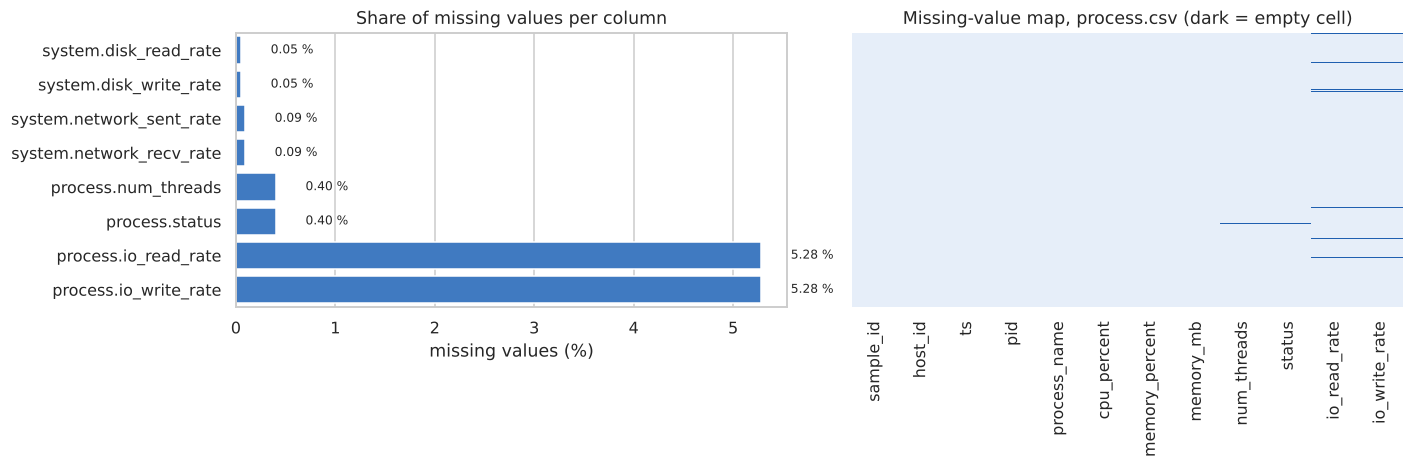

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
share = pd.concat(
    [
        missing_table(sysd[system.columns])["missing_%"].rename(lambda c: "system." + c),
        missing_table(process)["missing_%"].rename(lambda c: "process." + c),
    ]
).sort_values()
sns.barplot(x=share.values, y=share.index, color="#2a78d6", ax=axes[0])
axes[0].set_xlabel("missing values (%)")
axes[0].set_ylabel("")
axes[0].set_title("Share of missing values per column")
for i, v in enumerate(share.values):
    axes[0].text(v + 0.3, i, f"{v:.2f} %", va="center", fontsize=8)

# Missing-value map of 400 process rows: every light line is an empty cell
sample = process.sample(400, random_state=RANDOM_STATE).sort_index()
sns.heatmap(sample.isna(), cbar=False, yticklabels=False, cmap=["#e6eef9", "#1f5fb0"], ax=axes[1])
axes[1].set_title("Missing-value map, process.csv (dark = empty cell)")
save("step3_missing_values")

In [16]:
# Gaps in the time series: more than 7.5 s (1.5 sampling intervals) between two samples of one block
step = sysd["ts"].diff().dt.total_seconds()
same_block = sysd["session_id"] == sysd["session_id"].shift()
gaps = sysd.loc[same_block & (step > 7.5), ["ts", "session_id"]].assign(gap_seconds=step.round(1))
print("Gaps inside a session or the background block:", len(gaps))
print(gaps.rename(columns={"ts": "first sample after the gap"}).to_string(index=False))

Gaps inside a session or the background block: 5
      first sample after the gap session_id  gap_seconds
2026-01-05 09:12:12.515000+00:00         BG         10.0
2026-01-06 15:34:32.462000+00:00         S2          9.9
2026-01-06 15:42:12.474000+00:00         S2         15.0
2026-01-07 12:11:52.495000+00:00         S3         45.0
2026-01-09 14:18:27.495000+00:00         S5         10.0


### 3.1 Imputation strategy used

| Group | Columns | Missing | Technique | Why |
|---|---|---|---|---|
| System rates | `disk_read_rate`, `disk_write_rate`, `network_sent_rate`, `network_recv_rate` | 3 to 5 rows (0.05 - 0.09 %) | Drop the row | A rate needs two counter readings, so it is empty on the first sample after a restart or a counter reset; any fill would invent traffic (specification 10.2, operation 3) |
| Process I/O | `io_read_rate`, `io_write_rate` | 2641 rows (5.28 %) | Fill with 0 and add the indicator `io_denied` | The operating system hides the counters of root-owned processes; the refusal is information, so it gets a column of its own |
| Process status | `status` | 201 rows (0.40 %) | New category `unknown` | The process ended between the listing and the reading; a status cannot be guessed |
| Thread count | `num_threads` | 201 rows (0.40 %) | Median of the column | Few rows, and thread counts differ a lot between processes, so the median is a safe middle value |

The five gaps in the time series are not filled. Three of them (about 10 s each) are the rows removed in Step 2, one is a 15 s outage in S2 and one a 45 s outage in S3. The rolling windows of Step 8 are measured in seconds, so a gap shortens a window instead of stretching it over time that was never recorded.

In [17]:
# (a) system.csv - a rate needs two counter readings, so it is null on the first sample after a restart
#     or a counter reset (specification 10.2, operation 3): the row is dropped, nothing is invented
null_rate = sysd[RATE_FIELDS].isna().any(axis=1)
print("Rows with a null rate field:", int(null_rate.sum()))
display(sysd.loc[null_rate, ["ts", "session_id", "label"] + RATE_FIELDS])
sysd = sysd[~null_rate].reset_index(drop=True)
print("rows left:", len(sysd))

Rows with a null rate field: 5


,ts,session_id,label,disk_read_rate,disk_write_rate,network_sent_rate,network_recv_rate
0,2026-01-05 07:30:02.506000+00:00,BG,background,NaN,NaN,NaN,NaN
2422,2026-01-06 15:42:12.474000+00:00,S2,normal,NaN,NaN,NaN,NaN
3368,2026-01-07 11:36:02.496000+00:00,S3,normal,43540.4,376404.2,NaN,NaN
3790,2026-01-07 12:11:52.495000+00:00,S3,network,NaN,NaN,NaN,NaN
4884,2026-01-09 14:08:02.488000+00:00,S5,normal,223592.1,14548.7,NaN,NaN


rows left: 5622


In [18]:
# (b) process.csv - I/O rates are null where the OS denies access (root-owned processes): fill with 0
#     and keep an indicator column; status and num_threads are null when a process exits between
#     the listing and the reading
process["io_denied"] = process[["io_read_rate", "io_write_rate"]].isna().any(axis=1).astype(int)
process[["io_read_rate", "io_write_rate"]] = process[["io_read_rate", "io_write_rate"]].fillna(0.0)
process["status"] = process["status"].fillna("unknown")
process["num_threads"] = process["num_threads"].fillna(process["num_threads"].median())
print("Missing values left in process.csv:", int(process.isna().sum().sum()))
print(
    "Share of process rows with denied I/O counters:", round(process["io_denied"].mean() * 100, 1), "%"
)

Missing values left in process.csv: 0
Share of process rows with denied I/O counters: 5.3 %


### 3.2 Comparing imputation techniques (mean vs median vs forward fill vs interpolation vs KNN)

The numerical columns have no gaps left, so to *compare* the techniques fairly, 10 % of the values of three columns are hidden on purpose and each technique tries to recover them. `cpu_percent` is noisy but follows its neighbours, `ram_percent` is smooth, and `disk_write_rate` is almost zero with rare large bursts. The mean absolute error (MAE) against the true values shows which technique suits which kind of column.

In [19]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler

TARGETS = ["cpu_percent", "ram_percent", "disk_write_rate"]
context = [
    "cpu_percent",
    "ram_percent",
    "load_average",
    "process_count",
    "disk_write_rate",
    "network_recv_rate",
]
series = sysd[context].reset_index(drop=True)  # the time order is kept
rng = np.random.RandomState(RANDOM_STATE)
errors = {}
for target in TARGETS:
    hidden = rng.choice(np.arange(1, len(series) - 1), size=int(0.10 * len(series)), replace=False)
    truth = series.loc[hidden, target].to_numpy()
    masked = series.copy()
    masked.loc[hidden, target] = np.nan
    column = masked[[target]]
    filled = {
        "mean": SimpleImputer(strategy="mean").fit_transform(column)[:, 0],
        "median": SimpleImputer(strategy="median").fit_transform(column)[:, 0],
        "forward fill": masked[target].ffill().to_numpy(),
        "linear interpolation": masked[target].interpolate(method="linear").to_numpy(),
    }
    scaler = StandardScaler().fit(masked)  # z-scores, so that no column dominates the distance
    knn = KNNImputer(n_neighbors=5).fit_transform(scaler.transform(masked))
    filled["KNN (k=5)"] = scaler.inverse_transform(knn)[:, context.index(target)]
    errors[target] = {
        name: float(np.mean(np.abs(values[hidden] - truth))) for name, values in filled.items()
    }

mae = pd.DataFrame(errors)
with pd.option_context("display.float_format", "{:,.2f}".format):
    print("Mean absolute error when 10 % of a column is hidden:")
    print(mae.to_string())
print("\nTechnique with the lowest error:")
print(mae.idxmin().to_string())

Mean absolute error when 10 % of a column is hidden:
                      cpu_percent  ram_percent  disk_write_rate
mean                        10.84         4.96    36,323,454.07
median                       9.72         4.09    21,566,103.58
forward fill                 2.68         0.27     4,822,538.93
linear interpolation         1.86         0.23     4,706,700.58
KNN (k=5)                    3.91         2.90     8,743,691.56

Technique with the lowest error:
cpu_percent        linear interpolation
ram_percent        linear interpolation
disk_write_rate    linear interpolation


**Observations:** When a value is hidden, the neighbouring samples tell far more than the column as a whole. For `cpu_percent` linear interpolation has the smallest error (1.86, against 10.84 for the mean and 9.72 for the median), and for `ram_percent` it is 0.23 against 4.96 and 4.09; forward fill is a close second (2.68 and 0.27). KNN (3.91 and 2.90) is better than the mean but worse than interpolation, because the nearest rows in feature space are not the nearest in time. `disk_write_rate` is bursty, so even interpolation (an error of 4,706,700.58 bytes per second) cannot recover a burst it has not seen, but it still beats the mean (36,323,454.07) by a wide margin.

This is why the project does not fill the missing rates with a column statistic: those rows are dropped (Step 3.1), and where a value in a time series really has to be filled, interpolation or forward fill is the better choice.

## Step 4 - Visualise the numerical features

Fit rows (ordinary use before S5): 2825 | test rows (labelled, S5): 538


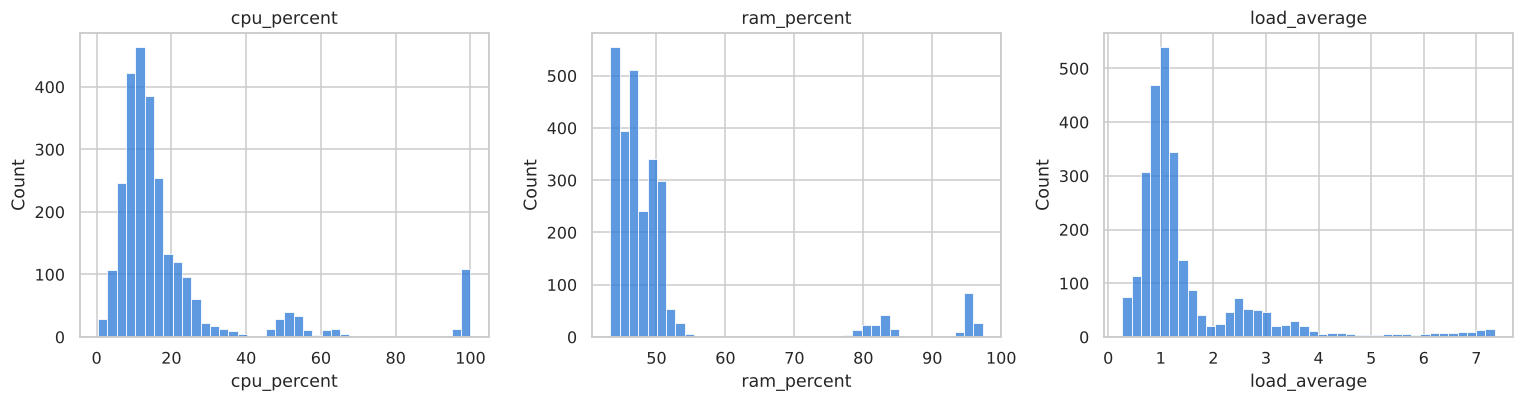

In [20]:
# From here on the labelled rows are plotted; the masks of the split (specification 10.3) are stored
sysd["is_test"] = sysd["scored"] & (sysd["session_id"] == "S5")  # opened once, at the end
sysd["is_fit"] = (
    sysd["label"].isin(["normal", "background"]) & ~sysd["trimmed"] & (sysd["session_id"] != "S5")
)  # rows used for any fit
S = sysd[sysd["scored"]]
print(
    "Fit rows (ordinary use before S5):",
    int(sysd["is_fit"].sum()),
    "| test rows (labelled, S5):",
    int(sysd["is_test"].sum()),
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["cpu_percent", "ram_percent", "load_average"]):
    sns.histplot(S[col], bins=40, color="#2a78d6", ax=ax)
    ax.set_title(col)
save("step4_histograms")

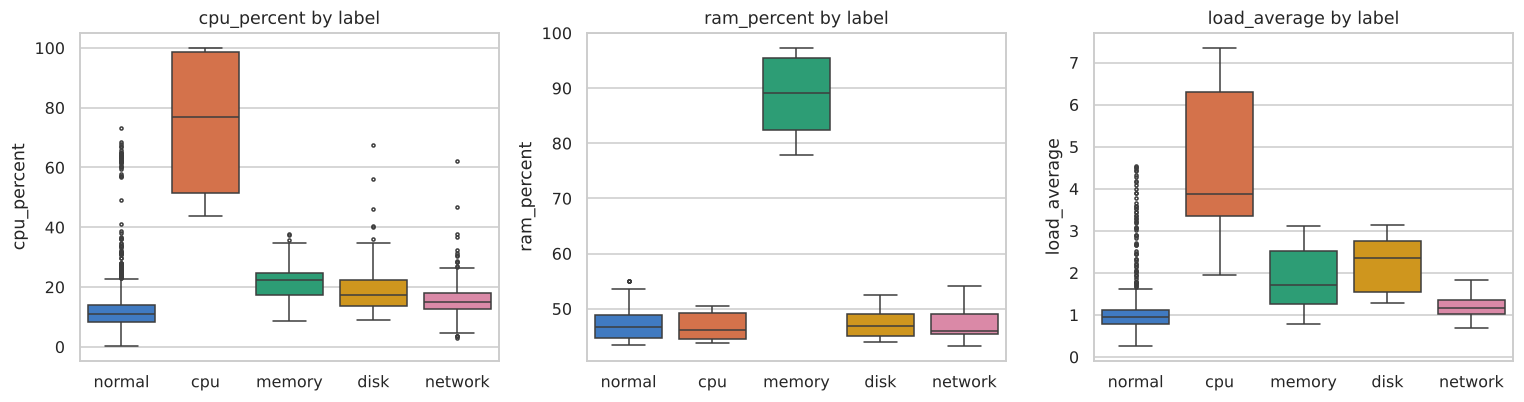

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["cpu_percent", "ram_percent", "load_average"]):
    sns.boxplot(
        data=S,
        x="label",
        y=col,
        hue="label",
        order=LABELS,
        hue_order=LABELS,
        palette=LABEL_COLORS,
        legend=False,
        fliersize=2,
        ax=ax,
    )
    ax.set_title(col + " by label")
    ax.set_xlabel("")
save("step4_boxplots")

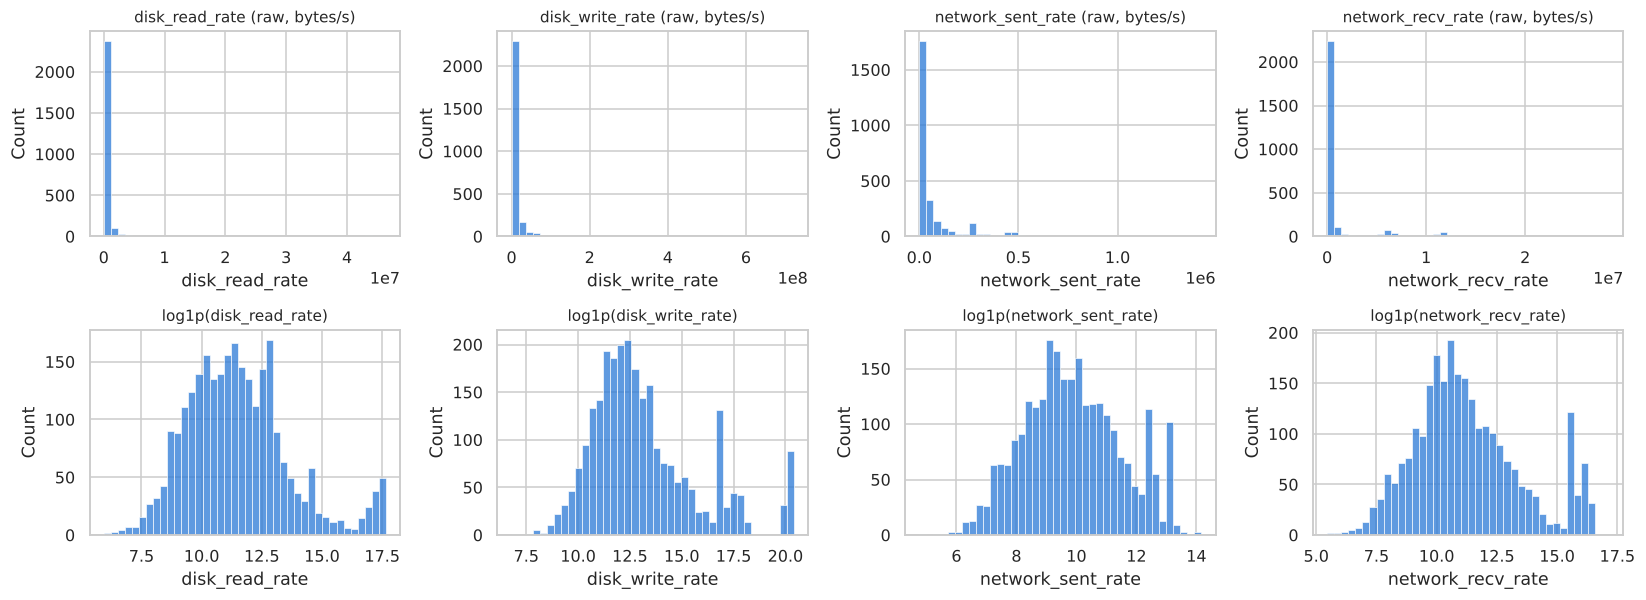

Skewness of the numerical columns of the labelled rows:
cpu_percent          2.76
ram_percent          2.83
swap_percent         5.17
load_average         2.61
process_count        1.75
disk_read_rate       4.65
disk_write_rate      4.45
network_sent_rate    3.24
network_recv_rate    3.33


In [22]:
# The four rate fields, raw (top) and after log1p (bottom): near zero most of the time, rare huge values
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for j, col in enumerate(RATE_FIELDS):
    sns.histplot(S[col], bins=40, color="#2a78d6", ax=axes[0, j])
    axes[0, j].set_title(col + " (raw, bytes/s)", fontsize=10)
    sns.histplot(np.log1p(S[col]), bins=40, color="#2a78d6", ax=axes[1, j])
    axes[1, j].set_title("log1p(" + col + ")", fontsize=10)
save("step4_rates_raw_log")
print("Skewness of the numerical columns of the labelled rows:")
skew_cols = [
    "cpu_percent",
    "ram_percent",
    "swap_percent",
    "load_average",
    "process_count",
] + RATE_FIELDS
print(S[skew_cols].skew().round(2).to_string())

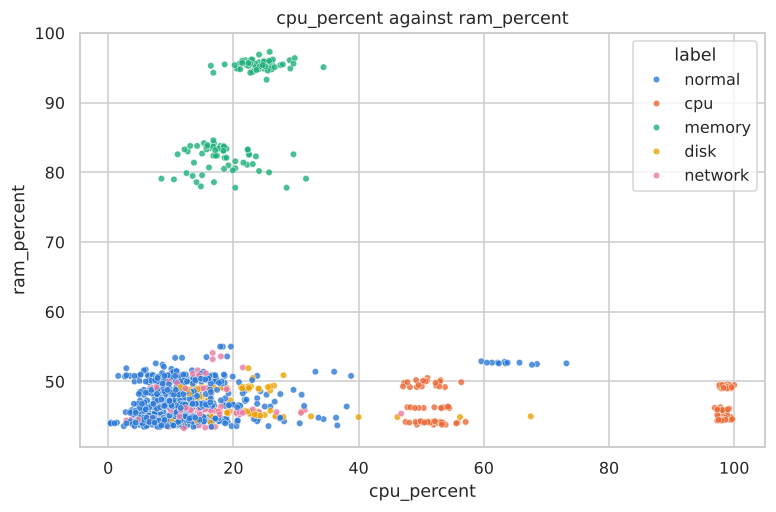

In [23]:
# Scatter plot - do the four stress types occupy different places in the CPU / RAM plane?
fig, ax = plt.subplots(figsize=(7.2, 4.8))
sample = S.sample(1200, random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample,
    x="cpu_percent",
    y="ram_percent",
    hue="label",
    hue_order=LABELS,
    palette=LABEL_COLORS,
    s=18,
    alpha=0.8,
    ax=ax,
)
ax.set_title("cpu_percent against ram_percent")
save("step4_scatter_cpu_ram")

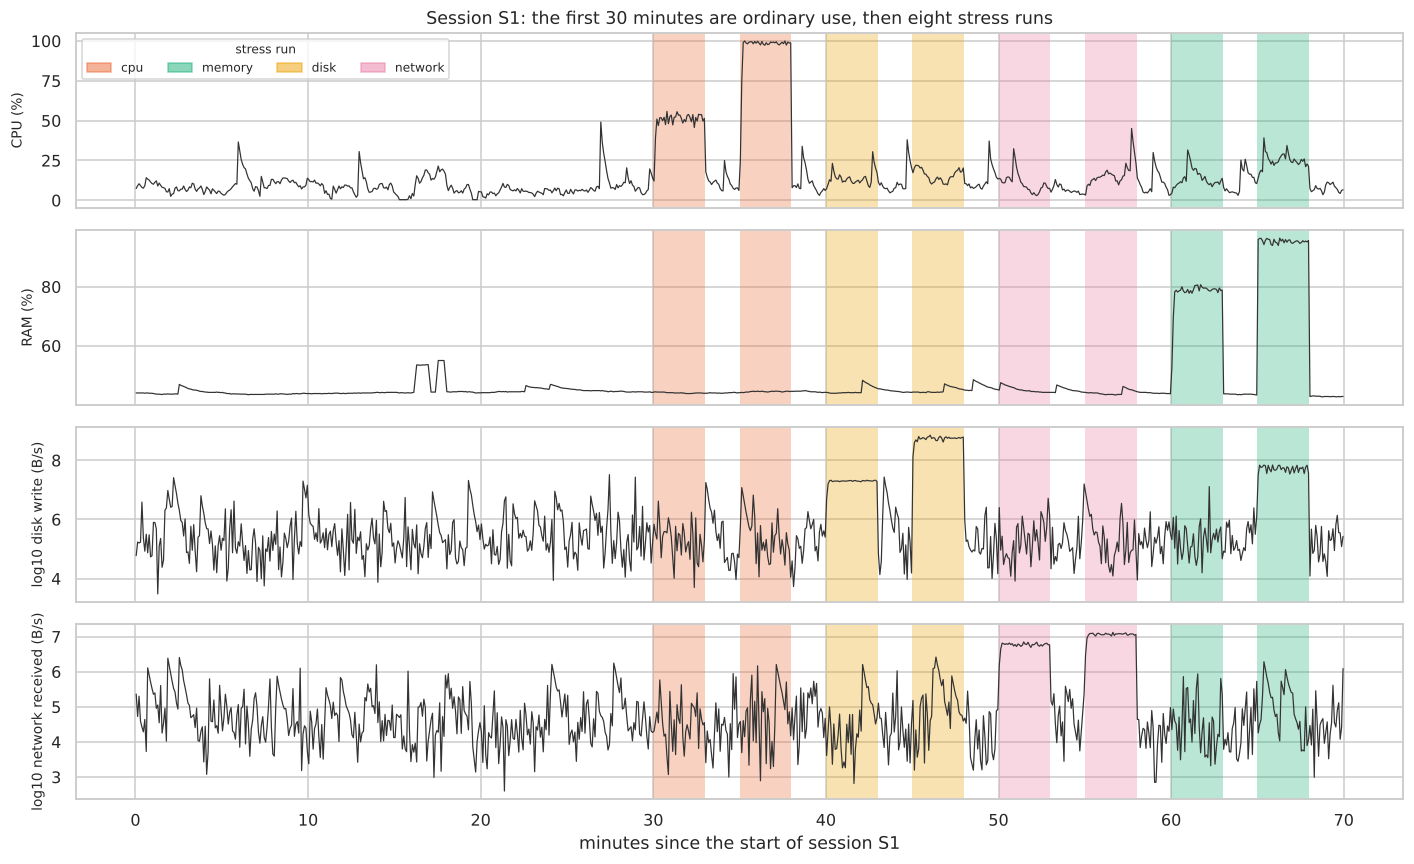

In [24]:
# Line plot - one whole session (S1): the stress runs are shaded, cooldown is left white
s1 = sysd[sysd["session_id"] == "S1"]
s1_runs = runs[runs["session_id"] == "S1"]
origin = s1_runs["started_at"].min()
minutes = (s1["ts"] - origin).dt.total_seconds() / 60
panels = [
    ("cpu_percent", s1["cpu_percent"], "CPU (%)"),
    ("ram_percent", s1["ram_percent"], "RAM (%)"),
    ("disk_write_rate", np.log10(1 + s1["disk_write_rate"]), "log10 disk write (B/s)"),
    ("network_recv_rate", np.log10(1 + s1["network_recv_rate"]), "log10 network received (B/s)"),
]
fig, axes = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for ax, (name, values, ylabel) in zip(axes, panels):
    ax.plot(minutes, values, color="#333333", linewidth=0.8)
    for r in s1_runs.itertuples():
        if r.label in LABELS and r.label != "normal":
            ax.axvspan(
                (r.started_at - origin).total_seconds() / 60,
                (r.ended_at - origin).total_seconds() / 60,
                color=LABEL_COLORS[r.label],
                alpha=0.30,
                linewidth=0,
            )
    ax.set_ylabel(ylabel, fontsize=9)
axes[-1].set_xlabel("minutes since the start of session S1")
handles = [plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[l], alpha=0.5) for l in LABELS[1:]]
axes[0].legend(
    handles, LABELS[1:], ncol=4, loc="upper left", fontsize=8, title="stress run", title_fontsize=8
)
axes[0].set_title("Session S1: the first 30 minutes are ordinary use, then eight stress runs")
save("step4_session_time_series")

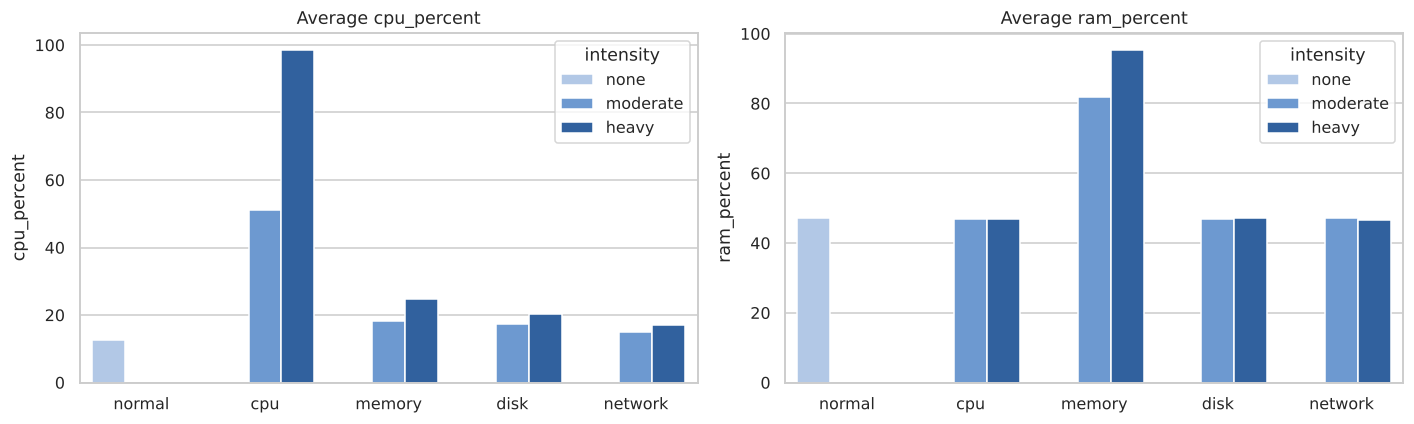

Median of the labelled rows for each label (the rates are in bytes per second):
         cpu_percent  ram_percent  load_average  disk_write_rate  network_recv_rate
label                                                                              
normal          10.9         46.7           0.9        219,760.9           42,068.7
cpu             77.1         46.2           3.9        245,263.8           60,644.9
memory          22.2         89.2           1.7     19,207,059.7           64,519.1
disk            17.5         46.8           2.4    195,222,678.2           52,798.7
network         14.9         45.9           1.2        171,527.6        6,648,568.2

Average cpu_percent and ram_percent for each label and intensity:
                   cpu_percent  ram_percent
label   intensity                          
cpu     heavy             98.6         46.9
        moderate          51.2         46.8
disk    heavy             20.3         47.1
        moderate          17.3         46.9
m

In [25]:
# Bar plot - average CPU and RAM per label and intensity
INTENSITY_COLORS = {"none": "#a9c6ef", "moderate": "#5c97e0", "heavy": "#1f5fb0"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["cpu_percent", "ram_percent"]):
    sns.barplot(
        data=S,
        x="label",
        y=col,
        hue="intensity",
        order=LABELS,
        hue_order=list(INTENSITY_COLORS),
        palette=INTENSITY_COLORS,
        errorbar=None,
        ax=ax,
    )
    ax.set_title("Average " + col)
    ax.set_xlabel("")
save("step4_bar_label_intensity")

print("Median of the labelled rows for each label (the rates are in bytes per second):")
medians = (
    S.groupby("label")[
        ["cpu_percent", "ram_percent", "load_average", "disk_write_rate", "network_recv_rate"]
    ]
    .median()
    .reindex(LABELS)
)
with pd.option_context("display.float_format", "{:,.1f}".format):
    print(medians.to_string())
print("\nAverage cpu_percent and ram_percent for each label and intensity:")
print(S.groupby(["label", "intensity"])[["cpu_percent", "ram_percent"]].mean().round(1).to_string())

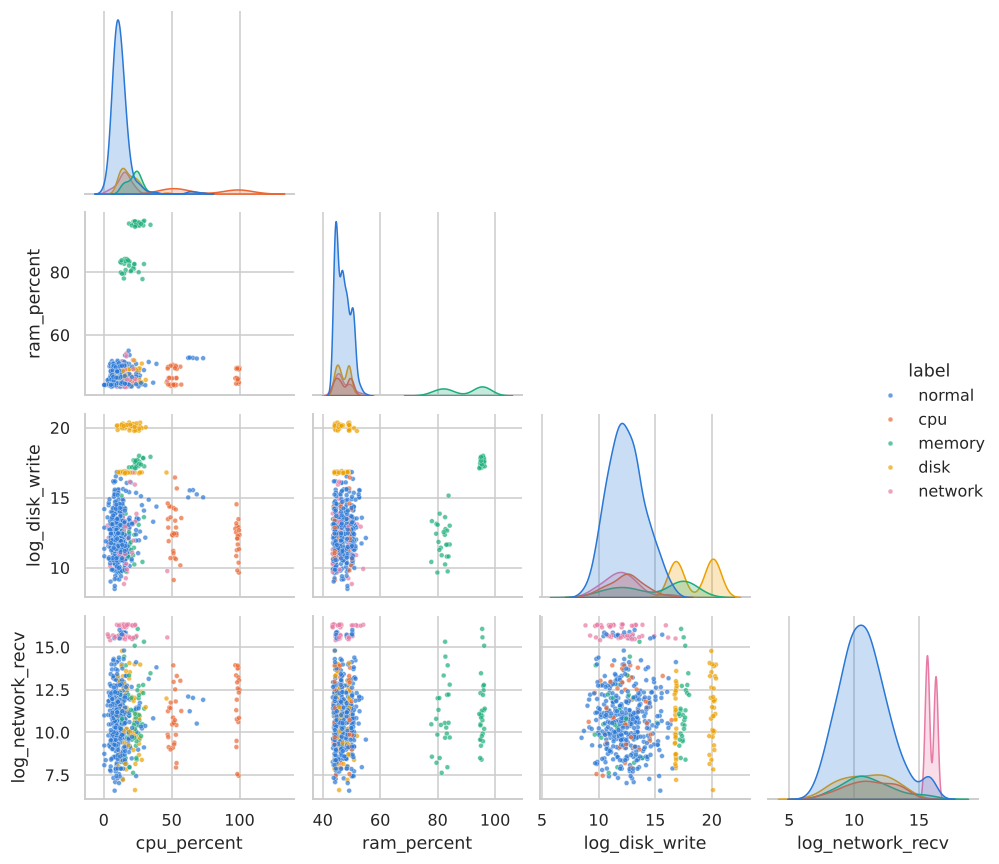

In [26]:
# Pair plot of four numerical columns coloured by label (600 rows)
sample = S.sample(600, random_state=RANDOM_STATE).assign(
    log_disk_write=lambda d: np.log1p(d["disk_write_rate"]),
    log_network_recv=lambda d: np.log1p(d["network_recv_rate"]),
)
sns.pairplot(
    sample[["cpu_percent", "ram_percent", "log_disk_write", "log_network_recv", "label"]],
    hue="label",
    hue_order=LABELS,
    palette=LABEL_COLORS,
    corner=True,
    height=2.0,
    plot_kws={"s": 10, "alpha": 0.7},
)
save("step4_pairplot")

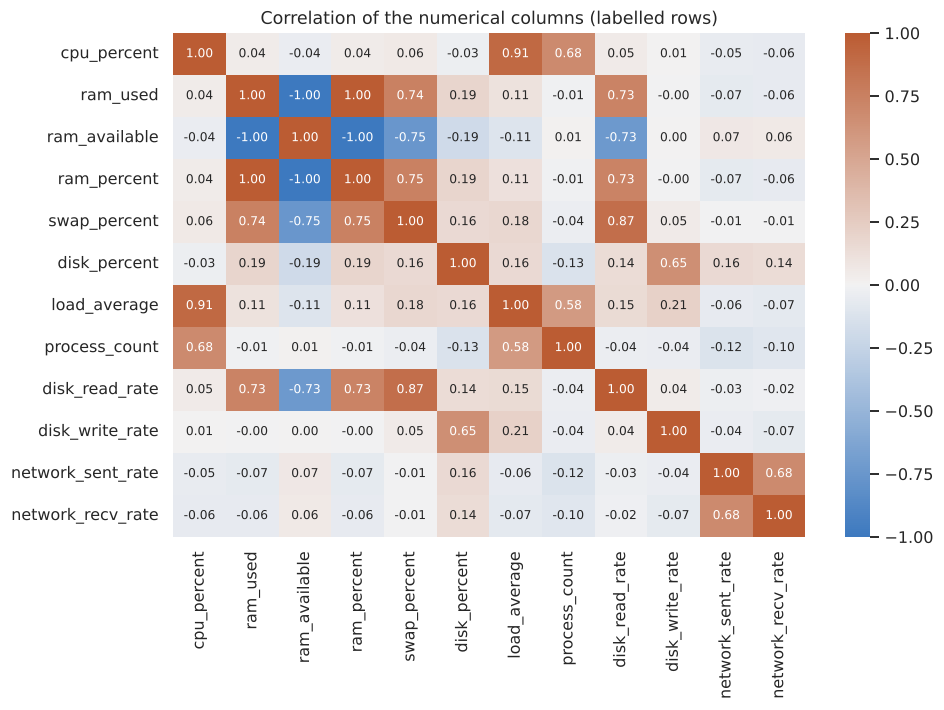

Correlation with ram_percent:
ram_used         0.997
ram_available   -1.000

Other pairs of columns with |r| above 0.6:
cpu_percent        load_average         0.91
swap_percent       disk_read_rate       0.87
ram_available      swap_percent        -0.75
ram_percent        swap_percent         0.75
ram_available      disk_read_rate      -0.73
ram_percent        disk_read_rate       0.73
network_sent_rate  network_recv_rate    0.68
cpu_percent        process_count        0.68
disk_percent       disk_write_rate      0.65


In [27]:
# Correlation heatmap - ram_used and ram_available should repeat ram_percent (specification 10.2, op. 5)
corr_cols = [
    "cpu_percent",
    "ram_used",
    "ram_available",
    "ram_percent",
    "swap_percent",
    "disk_percent",
    "load_average",
    "process_count",
] + RATE_FIELDS
fig, ax = plt.subplots(figsize=(9, 6.6))
corr = S[corr_cols].corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    vmin=-1,
    vmax=1,
    cmap=sns.diverging_palette(250, 25, s=80, l=50, center="light", as_cmap=True),
    ax=ax,
)
ax.set_title("Correlation of the numerical columns (labelled rows)")
save("step4_correlation_heatmap")
print("Correlation with ram_percent:")
print(S[["ram_used", "ram_available"]].corrwith(S["ram_percent"]).round(3).to_string())
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("\nOther pairs of columns with |r| above 0.6:")
print(
    pairs[
        (pairs.abs() > 0.6)
        & ~pairs.index.get_level_values(0).isin(["ram_used"])
        & ~pairs.index.get_level_values(1).isin(["ram_available", "ram_percent"])
    ]
    .sort_values(key=abs, ascending=False)
    .round(2)
    .to_string()
)

**Observations:**

* **Constant fields.** `cpu_count` is always 8 and `ram_total` never changes; `disk_percent` stays between 58.2 and 58.5. None of them can separate stress from ordinary use, so they are left out of the model features.
* **Fields that repeat each other.** `ram_used` (r = 0.997) and `ram_available` (r = -1.000) repeat `ram_percent`; the model keeps only the percentage.
* **Skewed fields.** The four rate fields have a skewness of 3.24 to 4.65 (`cpu_percent` 2.76, `ram_percent` 2.83): nearly all samples are close to zero and a few are enormous. After log1p the histograms are bell shaped, with small bumps on the right that are the stress runs.
* **What differs between normal and stress.** Every stress type has its own field. The median `cpu_percent` is 77.1 for cpu rows against 10.9 for normal rows, `ram_percent` is 89.2 for memory rows against 46.7, the disk write rate is 195,222,678.2 bytes/s for disk rows against 219,760.9, and the network receive rate is 6,648,568.2 for network rows against 42,068.7. The four fields do not overlap, so the detector has to watch all of them. Moderate and heavy runs differ in height: the average `cpu_percent` of the cpu runs is 51.2 and 98.6, and the average `ram_percent` of the memory runs is 81.9 and 95.4.
* **Other relationships.** `load_average` follows `cpu_percent` (r = 0.91) and `process_count` follows CPU too (0.68); `swap_percent` goes with `disk_read_rate` (0.87) because swapping reads pages back from disk, which is what the memory runs cause.

## Step 5 - Visualise the categorical features

The plots of this step also show the balance of the classes and what the process table reveals about the label - which decides what may be used as a feature. First the process table is reduced to one row per sample: the process with the highest CPU and the one with the most disk I/O.

In [28]:
# One row per sample from the process table: the process with the highest CPU and with the most I/O
process["io_total"] = process["io_read_rate"] + process["io_write_rate"]
by_cpu = process.sort_values(["sample_id", "cpu_percent"], ascending=[True, False]).drop_duplicates(
    "sample_id"
)
by_io = process.sort_values(["sample_id", "io_total"], ascending=[True, False]).drop_duplicates(
    "sample_id"
)
per_sample = (
    by_cpu[["sample_id", "process_name", "status"]]
    .rename(columns={"process_name": "top_cpu_process", "status": "top_cpu_status"})
    .merge(
        by_io[["sample_id", "process_name"]].rename(columns={"process_name": "top_io_process"}),
        on="sample_id",
    )
)
per_sample["n_zombie"] = (
    per_sample["sample_id"]
    .map((process["status"] == "zombie").groupby(process["sample_id"]).sum())
    .astype(int)
)
sysd = sysd.merge(per_sample, on="sample_id", how="left")
S = sysd[sysd["scored"]]
print("Samples without process rows:", int(sysd["top_cpu_process"].isna().sum()))
sysd[["ts", "label", "top_cpu_process", "top_cpu_status", "top_io_process", "n_zombie"]].sample(
    6, random_state=RANDOM_STATE
).sort_values("ts")

Samples without process rows: 0


,ts,label,top_cpu_process,top_cpu_status,top_io_process,n_zombie
80,2026-01-05 07:36:47.487000+00:00,background,firefox-esr,sleeping,firefox-esr,0
1115,2026-01-05 09:03:02.523000+00:00,background,firefox-esr,sleeping,python3,0
1255,2026-01-05 09:14:47.499000+00:00,background,code,sleeping,python3,0
3044,2026-01-06 16:34:12.536000+00:00,cooldown,firefox-esr,sleeping,wireshark,0
4486,2026-01-08 20:45:12.507000+00:00,disk,fio,disk-sleep,fio,0
4830,2026-01-09 14:03:52.505000+00:00,normal,Xorg,sleeping,firefox-esr,0


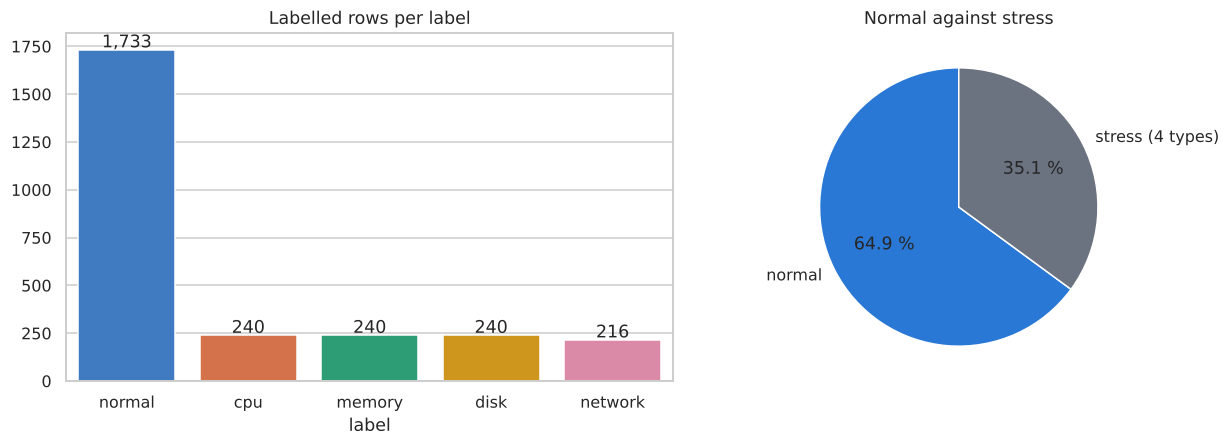

         rows  share_%
label                 
normal   1733     64.9
cpu       240      9.0
memory    240      9.0
disk      240      9.0
network   216      8.1

Normal 64.9 % | stress 35.1 %
A detector that never alarms is right on 64.9 % of the labelled rows.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
counts = S["label"].value_counts().reindex(LABELS)
sns.barplot(
    x=counts.index, y=counts.values, hue=counts.index, palette=LABEL_COLORS, legend=False, ax=axes[0]
)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 12, f"{v:,}", ha="center")
axes[0].set_title("Labelled rows per label")
binary = pd.Series(
    {
        "normal": int((S["label"] == "normal").sum()),
        "stress (4 types)": int((S["label"] != "normal").sum()),
    }
)
axes[1].pie(
    binary.values,
    labels=binary.index,
    colors=[LABEL_COLORS["normal"], "#6b7280"],
    autopct="%1.1f %%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
axes[1].set_title("Normal against stress")
save("step5_class_balance")
print(pd.DataFrame({"rows": counts, "share_%": (counts / counts.sum() * 100).round(1)}).to_string())
normal_share = binary["normal"] / binary.sum() * 100
print(f"\nNormal {normal_share:.1f} % | stress {100 - normal_share:.1f} %")
print(f"A detector that never alarms is right on {normal_share:.1f} % of the labelled rows.")

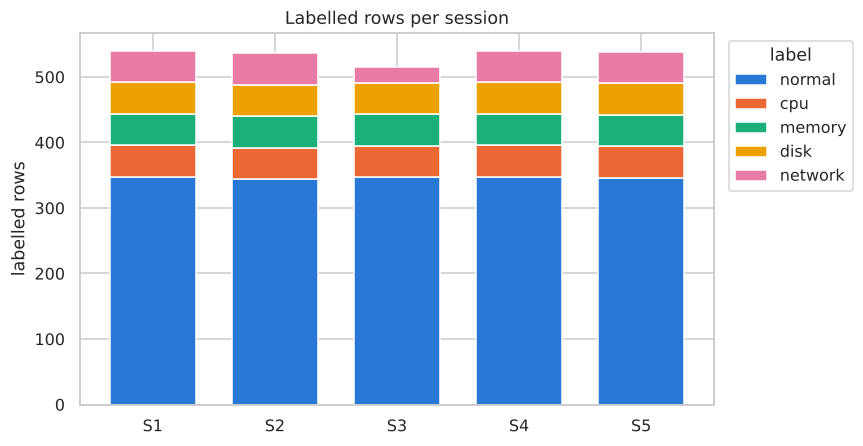

In [30]:
# Stacked bar - labelled rows per session (the void run of S3 and the lost samples are visible)
per_session = pd.crosstab(S["session_id"], S["label"])[LABELS]
ax = per_session.plot(
    kind="bar", stacked=True, color=[LABEL_COLORS[l] for l in LABELS], figsize=(8, 4.2), width=0.7
)
ax.set_xlabel("")
ax.set_ylabel("labelled rows")
ax.set_title("Labelled rows per session")
ax.legend(title="label", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
save("step5_rows_per_session")

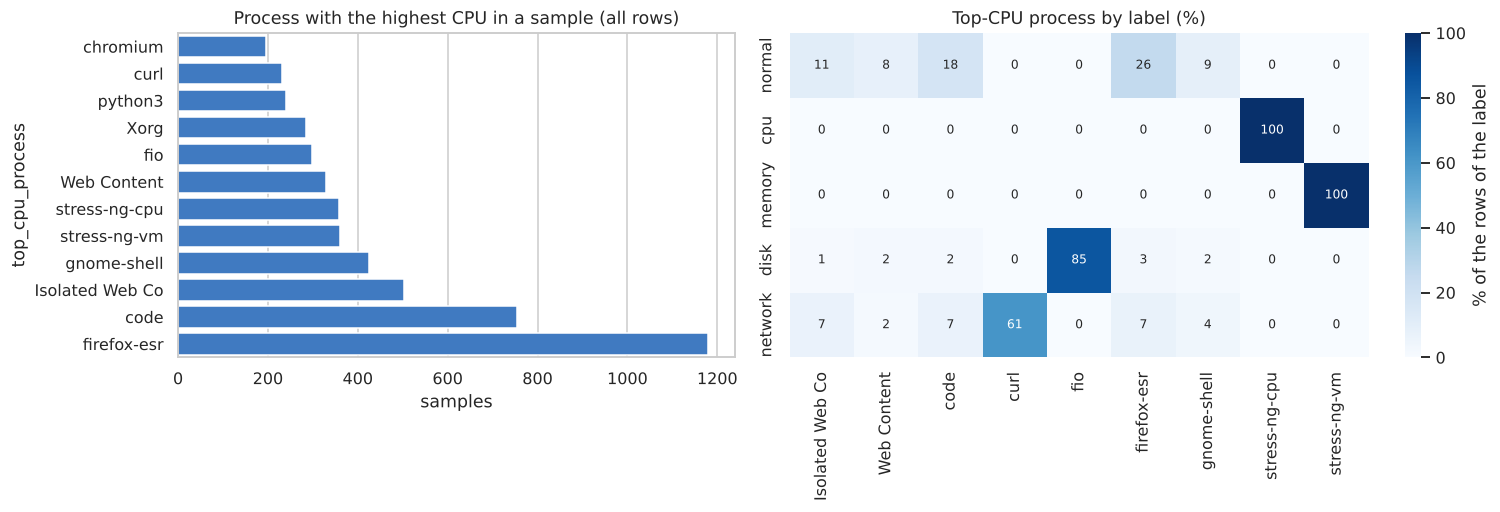

Most frequent top-CPU process in each label:
  normal   firefox-esr       26.1 % of the rows
  cpu      stress-ng-cpu    100.0 % of the rows
  memory   stress-ng-vm     100.0 % of the rows
  disk     fio               85.4 % of the rows
  network  curl              61.1 % of the rows


In [31]:
# Which process is on top? It reveals the stress tool - a leakage check
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
top = sysd["top_cpu_process"].value_counts().head(12).sort_values()
sns.barplot(x=top.values, y=top.index, color="#2a78d6", ax=axes[0])
axes[0].set_title("Process with the highest CPU in a sample (all rows)")
axes[0].set_xlabel("samples")
full = pd.crosstab(S["label"], S["top_cpu_process"], normalize="index").reindex(LABELS) * 100
share = full.loc[:, full.max() > 8]
sns.heatmap(
    share,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    annot_kws={"size": 8},
    ax=axes[1],
    cbar_kws={"label": "% of the rows of the label"},
)
axes[1].set_title("Top-CPU process by label (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
save("step5_top_process")
print("Most frequent top-CPU process in each label:")
for label, row in full.iterrows():
    print(f"  {label:8s} {row.idxmax():16s} {row.max():5.1f} % of the rows")

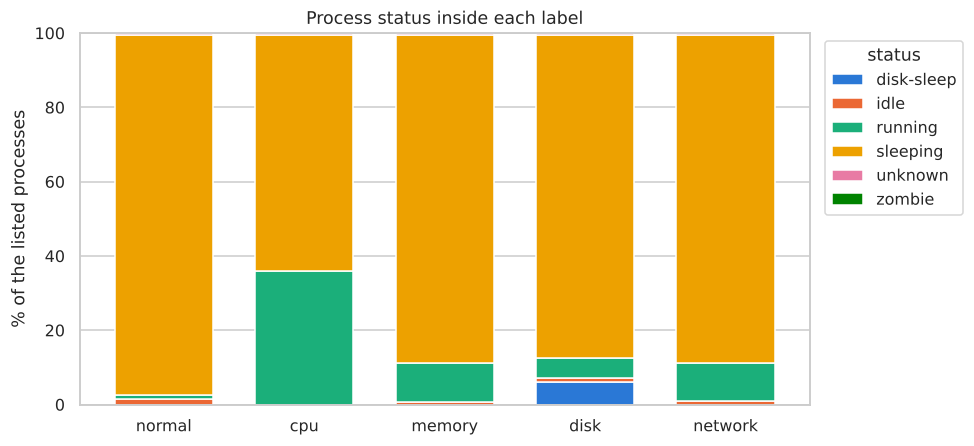

status   disk-sleep  idle  running  sleeping  unknown  zombie
label                                                        
normal          0.0   1.4      1.2      97.0      0.4     0.1
cpu             0.0   0.0     35.9      63.6      0.4     0.1
memory          0.0   0.7     10.5      88.2      0.5     0.0
disk            6.0   1.1      5.4      87.0      0.5     0.0
network         0.0   0.8     10.3      88.4      0.4     0.1


In [32]:
# Stacked bar - status of the listed processes inside each label
labelled = process.merge(S[["sample_id", "label"]], on="sample_id")
status_share = (
    pd.crosstab(labelled["label"], labelled["status"], normalize="index").reindex(LABELS) * 100
)
STATUS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
ax = status_share.plot(
    kind="bar", stacked=True, color=STATUS_COLORS[: status_share.shape[1]], figsize=(9, 4.2), width=0.7
)
ax.set_xlabel("")
ax.set_ylabel("% of the listed processes")
ax.set_title("Process status inside each label")
ax.legend(title="status", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
save("step5_status_by_label")
print(status_share.round(1).to_string())

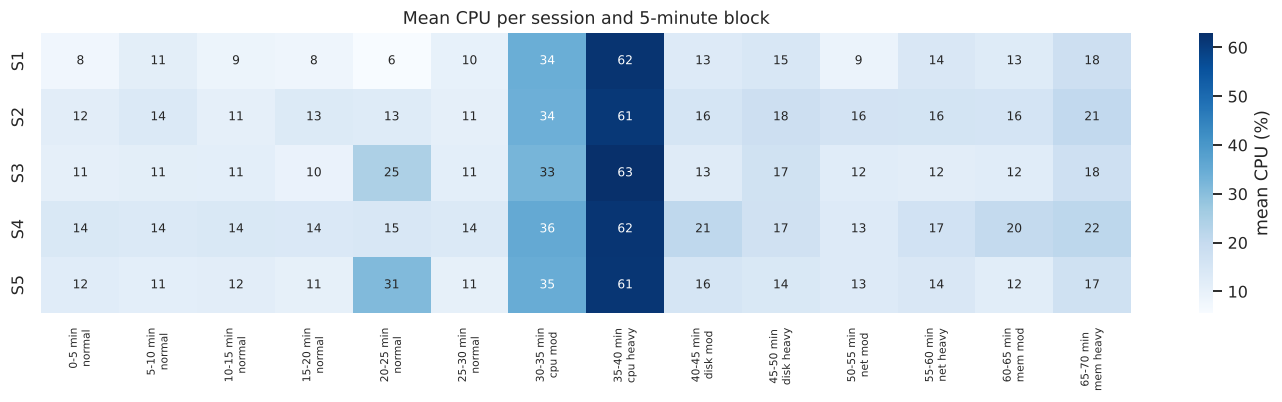

Mean CPU (%) per session and 5-minute block (minutes since the start of the session):
            0-5  5-10  10-15  15-20  20-25  25-30  30-35  35-40  40-45  45-50  50-55  55-60  60-65  65-70
session_id                                                                                               
S1            8    11      9      8      6     10     34     62     13     15      9     14     13     18
S2           12    14     11     13     13     11     34     61     16     18     16     16     16     21
S3           11    11     11     10     25     11     33     63     13     17     12     12     12     18
S4           14    14     14     14     15     14     36     62     21     17     13     17     20     22
S5           12    11     12     11     31     11     35     61     16     14     13     14     12     17


In [33]:
# Heatmap - mean CPU per session and 5-minute block; the order of the runs is fixed by the protocol
sessions = sysd[sysd["session_id"].str.startswith("S")].copy()
session_start = runs.groupby("session_id")["started_at"].min()
sessions["block"] = (
    (sessions["ts"] - sessions["session_id"].map(session_start)).dt.total_seconds() // 300
).astype(int)
heat = sessions.pivot_table(index="session_id", columns="block", values="cpu_percent", aggfunc="mean")
names = ["normal"] * 6 + [
    "cpu mod",
    "cpu heavy",
    "disk mod",
    "disk heavy",
    "net mod",
    "net heavy",
    "mem mod",
    "mem heavy",
]
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(
    heat,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    annot_kws={"size": 8},
    ax=ax,
    xticklabels=[f"{5 * b}-{5 * b + 5} min\n{n}" for b, n in zip(heat.columns, names)],
    cbar_kws={"label": "mean CPU (%)"},
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Mean CPU per session and 5-minute block")
plt.xticks(fontsize=7)
save("step5_session_block_heatmap")
print("Mean CPU (%) per session and 5-minute block (minutes since the start of the session):")
print(
    heat.round(0)
    .astype(int)
    .set_axis([f"{5 * b}-{5 * b + 5}" for b in heat.columns], axis=1)
    .to_string()
)

**Observations:**

* **Class balance.** 1,733 of the labelled rows (64.9 %) are normal and 35.1 % are stress rows (240 cpu, 240 memory, 240 disk and 216 network). A detector that never raises an alarm would be right on 64.9 % of the rows, so accuracy alone says little; the evaluation also needs precision, recall, F1 and ROC-AUC.
* **Sessions.** The five sessions have almost the same size (515 to 540 labelled rows); S3 is the smallest because its heavy network run was voided. The block heatmap shows that every session follows the same protocol: the mean CPU rises to 33 - 36 % in the 30-35 minute block (moderate cpu run) and to 61 - 63 % in the heavy block, while ordinary use stays at 6 - 15 %. Two ordinary-use blocks are busier (25 % in S3 and 31 % in S5 at 20-25 minutes): ordinary use contains short busy episodes, such as a compile or a download, that a detector must not mistake for stress.
* **The process table reveals the label.** The process with the highest CPU is `stress-ng-cpu` in 100.0 % of the cpu rows, `stress-ng-vm` in 100.0 % of the memory rows, `fio` in 85.4 % of the disk rows and `curl` in 61.1 % of the network rows, while in ordinary use it is a browser, an editor or a desktop process (`firefox-esr` leads with 26.1 %). A model that sees process names would learn the name of the stress tool instead of the symptom, so process names are kept out of the model features; Step 9 measures the effect.
* **Process status.** 35.9 % of the listed processes in the cpu rows are `running` against 1.2 % in normal rows, and `disk-sleep` (waiting for the disk) appears only in the disk rows (6.0 %).

## Step 6 - Convert text to numbers (encoding)

Each categorical column is encoded with the technique that fits its number of categories (Step 1) and its order:

| Technique | Applied to | Reason |
|---|---|---|
| Label encoding | `label` (7 values) and the target `is_stress` (0 = normal, 1 = any stress type) | The label is the target, not an input; one number per class is enough |
| Ordinal encoding | `intensity` (none < moderate < heavy) | The categories have a natural order, which the numbers 0, 1, 2 keep |
| One-hot encoding | `top_cpu_status`, the status of the busiest process (6 values) | Few categories without an order; one 0/1 column for each, the first category is dropped as the reference |
| Binary encoding | `top_cpu_process` (23 values) | Too many categories for one-hot; the category number written in binary needs only 5 columns |
| Frequency encoding | `top_io_process` | A process becomes how common it is in ordinary use; a process never seen there gets 0 |

The process-derived columns serve two purposes: they demonstrate the encodings, and they let Step 9 measure how much label information the process names carry. They are not among the eleven model features.

In [34]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder

enc = sysd[
    ["session_id", "ts", "label", "intensity", "top_cpu_process", "top_cpu_status", "top_io_process"]
].copy()

# ---- 6.1 Label encoding: every label gets an integer (alphabetical order); is_stress is the target
le = LabelEncoder().fit(enc["label"])
enc["label_code"] = le.transform(enc["label"])
enc["is_stress"] = enc["label"].isin(["cpu", "memory", "disk", "network"]).astype(int)
print(
    "All labels:",
    ", ".join(f"{name} = {code}" for name, code in zip(le.classes_, le.transform(le.classes_))),
)
print("\nLabels that are scored:")
print(
    enc.loc[sysd["scored"], ["label", "label_code", "is_stress"]]
    .drop_duplicates()
    .sort_values("label_code")
    .to_string(index=False)
)

All labels: background = 0, cooldown = 1, cpu = 2, disk = 3, memory = 4, network = 5, normal = 6

Labels that are scored:
  label  label_code  is_stress
    cpu           2          1
   disk           3          1
 memory           4          1
network           5          1
 normal           6          0


In [35]:
# ---- 6.2 Ordinal encoding: intensity has a natural order none < moderate < heavy
INTENSITY_ORDER = ["none", "moderate", "heavy"]
enc["intensity_code"] = (
    OrdinalEncoder(categories=[INTENSITY_ORDER]).fit_transform(enc[["intensity"]]).ravel().astype(int)
)
print(
    enc[["intensity", "intensity_code"]]
    .drop_duplicates()
    .sort_values("intensity_code")
    .to_string(index=False)
)

intensity  intensity_code
     none               0
 moderate               1
    heavy               2


In [36]:
# ---- 6.3 One-hot encoding: status of the top-CPU process (no order, few categories);
#      drop="first" avoids the dummy-variable trap
ohe = OneHotEncoder(drop="first", sparse_output=False)
status_cols = pd.DataFrame(
    ohe.fit_transform(enc[["top_cpu_status"]]),
    index=enc.index,
    columns=[c.replace("top_cpu_status_", "status_") for c in ohe.get_feature_names_out()],
)
enc = pd.concat([enc, status_cols], axis=1)
print("categories:", ", ".join(ohe.categories_[0]))
print("dropped as the reference:", ohe.categories_[0][0])
print("one-hot columns:", ", ".join(status_cols.columns))

categories: disk-sleep, idle, running, sleeping, unknown, zombie
dropped as the reference: disk-sleep
one-hot columns: status_idle, status_running, status_sleeping, status_unknown, status_zombie


In [37]:


# ---- 6.4 Binary encoding: top_cpu_process has many categories; the category number is written
#      in binary, one column per bit (log2 n columns instead of n)
def binary_encode(series, prefix):
    codes, categories = pd.factorize(series, sort=True)
    n_bits = int(np.ceil(np.log2(len(categories))))
    bits = pd.DataFrame({f"{prefix}_b{k}": (codes >> k) & 1 for k in range(n_bits)}, index=series.index)
    return bits, dict(zip(categories, range(len(categories))))


process_bits, process_codes = binary_encode(enc["top_cpu_process"], "top_cpu_process")
enc = pd.concat([enc, process_bits], axis=1)
n_cat = len(process_codes)
print(f"{n_cat} categories -> {process_bits.shape[1]} binary columns (one-hot would need {n_cat})")
for name in ["firefox-esr", "fio", "stress-ng-cpu"]:
    code = process_codes[name]
    print(
        f"  {name:14s} code {code:2d} -> bits {[(code >> k) & 1 for k in range(process_bits.shape[1])]}"
    )

23 categories -> 5 binary columns (one-hot would need 23)
  firefox-esr    code  9 -> bits [1, 0, 0, 1, 0]
  fio            code  8 -> bits [0, 0, 0, 1, 0]
  stress-ng-cpu  code 19 -> bits [1, 1, 0, 0, 1]


In [38]:
# ---- 6.5 Frequency encoding: top_io_process becomes how common it is in ordinary use.
#      The frequencies come from the fit rows only, so a process never seen in ordinary use gets 0
freq = enc.loc[sysd["is_fit"], "top_io_process"].value_counts(normalize=True)
enc["top_io_process_freq"] = enc["top_io_process"].map(freq).fillna(0.0)
print("Most common I/O-heavy processes in the fit rows:")
print(freq.head(6).round(3).to_string())
unseen = sorted(set(enc["top_io_process"]) - set(freq.index))
print("Never top-I/O in ordinary use (encoded as 0):", ", ".join(unseen))
enc[["top_cpu_process", "top_cpu_status", "top_io_process", "top_io_process_freq"]].sample(
    5, random_state=RANDOM_STATE
).sort_index()

Most common I/O-heavy processes in the fit rows:
top_io_process
code               0.246
firefox-esr        0.244
python3            0.135
Isolated Web Co    0.124
Web Content        0.096
chromium           0.065
Never top-I/O in ordinary use (encoded as 0): fio


,top_cpu_process,top_cpu_status,top_io_process,top_io_process_freq
80,firefox-esr,sleeping,firefox-esr,0.244248
1255,code,sleeping,python3,0.134867
3044,firefox-esr,sleeping,wireshark,0.005310
4486,fio,disk-sleep,fio,0.000000
4830,Xorg,sleeping,firefox-esr,0.244248


**Observations:** Every text column is now numerical: the 7 labels became the codes 0 to 6 and the target `is_stress` (0 for `normal`, 1 for the four stress types), `intensity` became 0, 1, 2, the status of the busiest process became 5 one-hot columns, the 23 process names became 5 binary columns instead of 23 one-hot columns, and `top_io_process` became its frequency in ordinary use (0.246 for `code`, 0.244 for `firefox-esr`). The frequencies were counted on the fit rows only. The only process with the frequency 0 is `fio`, the disk stress tool, so the value 0 itself points at a stress run - one more sign that process names leak the label.

## Step 7 - Scale the numerical features

The numerical columns live on very different ranges (`cpu_percent` 0-100, `process_count` about 300, the rates up to 10^8 bytes per second). Distance-based models (LOF, K-Means, KNN) are dominated by the column with the largest range, so the values are brought to a similar scale. Four scalers are compared on the same columns; each learns its parameters from the **fit rows** only (ordinary use before S5) and is then applied to the labelled rows:

| Scaler | Formula | Result | When to use |
|---|---|---|---|
| **StandardScaler** | (x - mean) / std | mean 0, std 1 | default for distance-based models such as LOF |
| **MinMaxScaler** | (x - min) / (max - min) | 0 to 1 | neural networks, when a bounded range is wanted |
| **RobustScaler** | (x - median) / IQR | median 0 | when outliers exist |
| **Normalizer** | x / \|x\| per row | every row has length 1 | direction-based data; shown for comparison |

In [39]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, Normalizer

SCALE_COLS = [
    "cpu_percent",
    "ram_percent",
    "disk_write_rate",
    "network_recv_rate",
    "load_average",
    "process_count",
]
fit_part = sysd.loc[sysd["is_fit"], SCALE_COLS]  # the scalers learn from these rows only
view = S[SCALE_COLS]
scaled = {"raw": view}
for name, scaler in {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}.items():
    scaled[name] = pd.DataFrame(
        scaler.fit(fit_part).transform(view), columns=SCALE_COLS, index=view.index
    )
scaled["Normalizer"] = pd.DataFrame(
    Normalizer().fit_transform(view), columns=SCALE_COLS, index=view.index
)

rows = [
    (name, col, frame[col].mean(), frame[col].std(), frame[col].min(), frame[col].max())
    for name, frame in scaled.items()
    for col in ["cpu_percent", "disk_write_rate"]
]
with pd.option_context("display.float_format", "{:.4g}".format):
    print(
        pd.DataFrame(rows, columns=["scaler", "column", "mean", "std", "min", "max"]).to_string(
            index=False
        )
    )

        scaler          column      mean       std       min       max
           raw     cpu_percent     19.81     20.58       0.4       100
           raw disk_write_rate  2.87e+07 1.147e+08     887.9 7.221e+08
StandardScaler     cpu_percent     1.025     2.481    -1.316     10.69
StandardScaler disk_write_rate     2.656     11.44   -0.2048     71.76
  MinMaxScaler     cpu_percent    0.2609    0.2766         0     1.339
  MinMaxScaler disk_write_rate    0.2149     0.859         0     5.406
  RobustScaler     cpu_percent      1.54     3.165    -1.446     13.88
  RobustScaler disk_write_rate     41.27     166.3   -0.3348      1046
    Normalizer     cpu_percent 9.718e-05 0.0002742 1.588e-08  0.005353
    Normalizer disk_write_rate    0.7605    0.3573 0.0003031         1


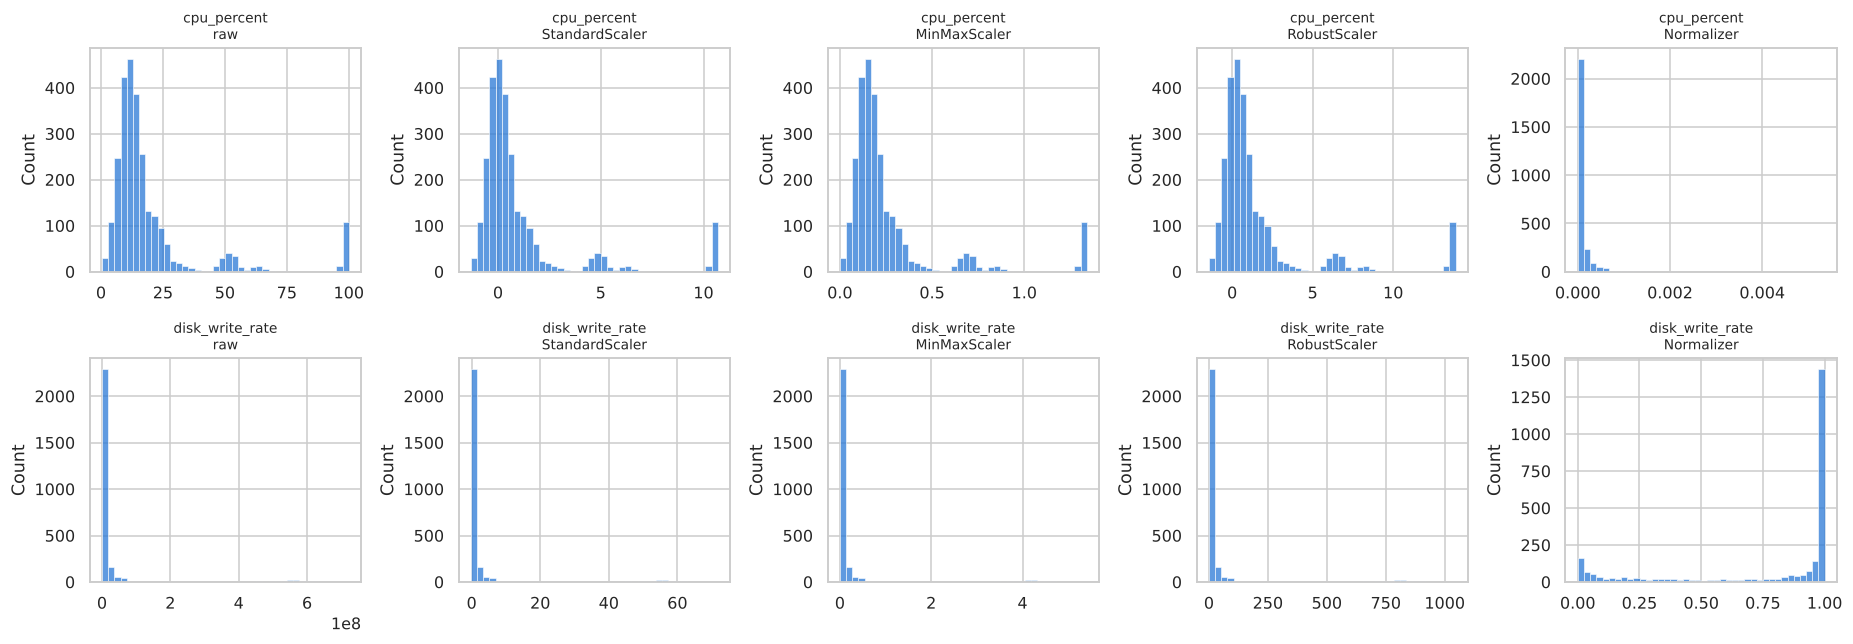

In [40]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for j, (name, frame) in enumerate(scaled.items()):
    for i, col in enumerate(["cpu_percent", "disk_write_rate"]):
        sns.histplot(frame[col], bins=40, color="#2a78d6", ax=axes[i, j])
        axes[i, j].set_title(f"{col}\n{name}", fontsize=9)
        axes[i, j].set_xlabel("")
save("step7_scalers")

### 7.1 Which models need scaling?
Isolation Forest chooses split points between the smallest and the largest value of a column, so a linear rescaling does not change its trees. LOF compares distances, so a column with a huge range decides everything. The experiment trains both on the six raw columns with and without `StandardScaler` and scores the test session S5 (the labels are used only to compute the ROC-AUC).

In [41]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score

X_fit = sysd.loc[sysd["is_fit"], SCALE_COLS]
X_test = sysd.loc[sysd["is_test"], SCALE_COLS]
y_test = enc.loc[sysd["is_test"], "is_stress"]
standard = StandardScaler().fit(X_fit)
auc, iso_scores = {}, {}
for setting, (a, b) in {
    "raw columns": (X_fit, X_test),
    "StandardScaler": (standard.transform(X_fit), standard.transform(X_test)),
}.items():
    iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(a)
    iso_scores[setting] = -iso.score_samples(b)
    lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(a)
    auc[setting] = {
        "Isolation Forest": roc_auc_score(y_test, iso_scores[setting]),
        "LOF": roc_auc_score(y_test, -lof.score_samples(b)),
    }
print("ROC-AUC on the test session S5 (labels used for scoring only):")
print(pd.DataFrame(auc).round(3).to_string())
same = np.allclose(iso_scores["raw columns"], iso_scores["StandardScaler"])
print("\nIsolation Forest scores identical with and without scaling:", same)

ROC-AUC on the test session S5 (labels used for scoring only):
                  raw columns  StandardScaler
Isolation Forest        0.915           0.915
LOF                     0.709           0.833

Isolation Forest scores identical with and without scaling: True


**Observations:** All four scalers learn their parameters on the fit rows (ordinary use), so the labelled rows show how far stress lies outside it. After `StandardScaler` the labelled `cpu_percent` has a mean of 1.025 and a maximum of 10.69 standard deviations of ordinary use; for `disk_write_rate` the maximum is 71.76. `MinMaxScaler` does not keep the rows inside 0 - 1 (maxima 1.339 and 5.406) because the stress rows lie beyond the range of ordinary use. `RobustScaler` stretches the bursty `disk_write_rate` most (maximum 1046), because its inter-quartile range is tiny. `Normalizer` works on rows, not columns: it squeezes `cpu_percent` to a mean of 9.718e-05 and pushes `disk_write_rate` towards 1 (mean 0.7605), which erases the meaning of both columns, so it is not suitable here.

The experiment of 7.1 confirms the specification: the Isolation Forest scores are identical with and without scaling (ROC-AUC 0.915 both times), whereas LOF improves from 0.709 to 0.833 when the columns are standardised. `StandardScaler`, fitted on the training rows only, therefore belongs inside the LOF pipeline and nowhere else.

## Step 8 - Create new features (feature construction)

New columns are derived from the existing ones so that the information an operator would look for is available to the model directly. The eleven features of the project (specification 10.2, operations 6 to 9) are built first, in one function that is later saved as `features.py`; then further candidate features, transformations, capping, PCA and a K-Means label are explored.

In [42]:
WINDOW = "30s"  # trailing window measured in seconds, not in rows
FEATURES = [
    "cpu_percent",
    "cpu_roll_mean_30s",
    "cpu_roll_std_30s",
    "ram_percent",
    "swap_delta_30s",
    "log_disk_read_rate",
    "log_disk_write_rate",
    "log_network_sent_rate",
    "log_network_recv_rate",
    "load_per_core",
    "process_count",
]


def build_features(d):
    """The 11 features of specification 10.2 for the rows of ONE host, sorted by time."""
    s = d.set_index("ts")
    out = pd.DataFrame(index=d.index)
    out["cpu_percent"] = d["cpu_percent"].to_numpy()
    cpu_window = s["cpu_percent"].rolling(WINDOW)  # the samples of the last 30 seconds
    out["cpu_roll_mean_30s"] = cpu_window.mean().to_numpy()
    out["cpu_roll_std_30s"] = cpu_window.std().fillna(0.0).to_numpy()  # one sample: std is taken as 0
    out["ram_percent"] = d["ram_percent"].to_numpy()
    out["swap_delta_30s"] = (
        s["swap_percent"].rolling(WINDOW).apply(lambda w: w[-1] - w[0], raw=True).to_numpy()
    )
    for col in RATE_FIELDS:  # operation 6: log1p of the four rates
        out["log_" + col] = np.log1p(d[col].to_numpy())
    out["load_per_core"] = (d["load_average"] / d["cpu_count"]).to_numpy()  # operation 7
    out["process_count"] = d["process_count"].to_numpy()
    return out[FEATURES]


feat = build_features(sysd)  # one host in this recording
print("Feature rows:", feat.shape, "| missing values:", int(feat.isna().sum().sum()))
with pd.option_context("display.float_format", "{:.4g}".format):
    display(feat.agg(["mean", "std", "min", "median", "max"]).T)

Feature rows: (5622, 11) | missing values: 0


,mean,std,min,median,max
cpu_percent,16.76,17.99,0.4,11.6,100
cpu_roll_mean_30s,16.76,17.12,0.4,12.08,99.27
cpu_roll_std_30s,3.332,4.925,0,1.882,49.78
ram_percent,49.77,10.45,42.7,47.3,97.3
swap_delta_30s,0.08221,0.4285,-0.1,0,2.8
log_disk_read_rate,11.38,2.109,5.746,11.11,18.35
log_disk_write_rate,13.03,2.38,6.79,12.56,20.4
log_network_sent_rate,9.782,1.593,4.763,9.671,14.29
log_network_recv_rate,11.17,2.174,4.992,10.88,17.17
load_per_core,0.1786,0.1458,0.0275,0.1313,0.9475


In [43]:
# Evidence for operation 8: at the start of the first heavy CPU run of S1 the raw value jumps at once,
# the rolling mean follows within 30 s and the rolling std peaks while the change is in the window
start = runs[(runs["session_id"] == "S1") & (runs["label"] == "cpu") & (runs["intensity"] == "heavy")][
    "started_at"
].iloc[0]
near = (sysd["ts"] >= start - pd.Timedelta(seconds=20)) & (
    sysd["ts"] <= start + pd.Timedelta(seconds=60)
)
table = pd.concat(
    [sysd.loc[near, ["ts", "cpu_percent"]], feat.loc[near, ["cpu_roll_mean_30s", "cpu_roll_std_30s"]]],
    axis=1,
)
table["ts"] = table["ts"].dt.strftime("%H:%M:%S")
print(f"CPU features around the start of the first heavy CPU run of S1 (starts {start:%H:%M:%S} UTC):")
print(table.round(1).to_string(index=False))

CPU features around the start of the first heavy CPU run of S1 (starts 10:35:00 UTC):
      ts  cpu_percent  cpu_roll_mean_30s  cpu_roll_std_30s
10:34:42          6.8               11.5               4.1
10:34:47          7.7                9.2               2.4
10:34:52          7.8                9.0               2.2
10:34:57          6.2                7.6               1.0
10:35:02         24.6               10.1               7.1
10:35:07         74.9               19.4              25.3
10:35:12         99.0               36.7              40.2
10:35:17        100.0               45.7              43.8
10:35:22         98.7               67.2              41.7
10:35:27         98.2               71.7              39.8
10:35:32         99.2               84.9              28.1
10:35:37         99.5               95.6               9.2
10:35:42         99.5               99.2               0.6
10:35:47         98.2               98.9               0.6
10:35:52         99.7        

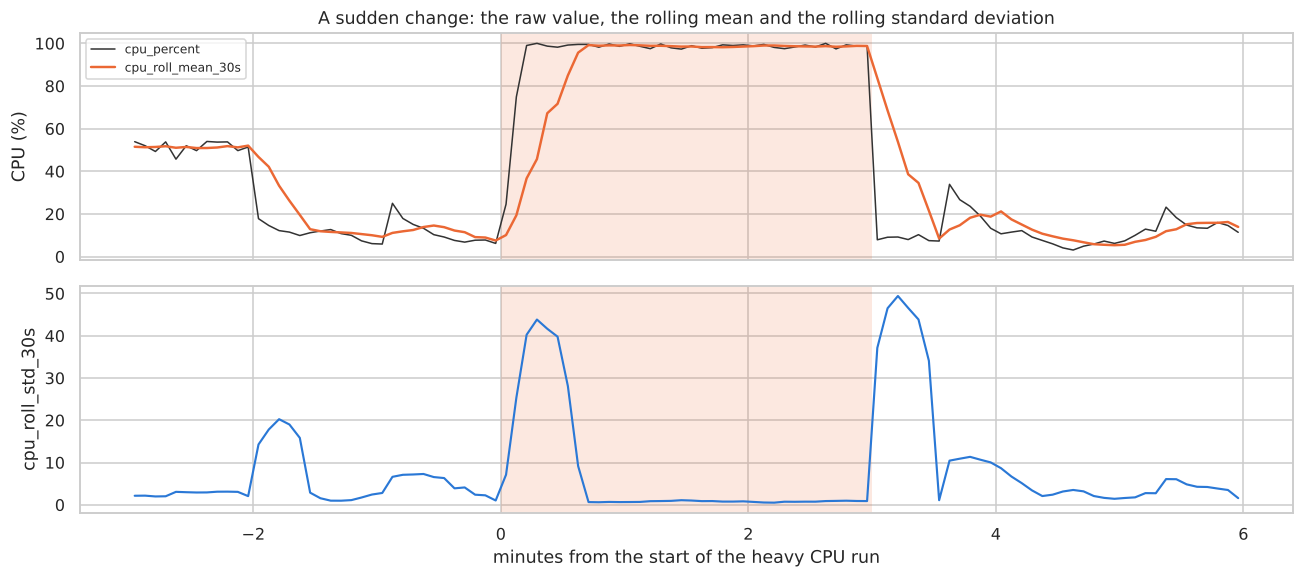

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.4), sharex=True)
window = (sysd["ts"] >= start - pd.Timedelta(minutes=3)) & (
    sysd["ts"] <= start + pd.Timedelta(minutes=6)
)
t = (sysd.loc[window, "ts"] - start).dt.total_seconds() / 60
axes[0].plot(t, sysd.loc[window, "cpu_percent"], color="#333333", linewidth=1, label="cpu_percent")
axes[0].plot(
    t, feat.loc[window, "cpu_roll_mean_30s"], color="#eb6834", linewidth=1.6, label="cpu_roll_mean_30s"
)
axes[0].set_ylabel("CPU (%)")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(t, feat.loc[window, "cpu_roll_std_30s"], color="#2a78d6", linewidth=1.4)
axes[1].set_ylabel("cpu_roll_std_30s")
axes[1].set_xlabel("minutes from the start of the heavy CPU run")
for ax in axes:
    ax.axvspan(0, 3, color=LABEL_COLORS["cpu"], alpha=0.15, linewidth=0)
axes[0].set_title("A sudden change: the raw value, the rolling mean and the rolling standard deviation")
save("step8_rolling_features")

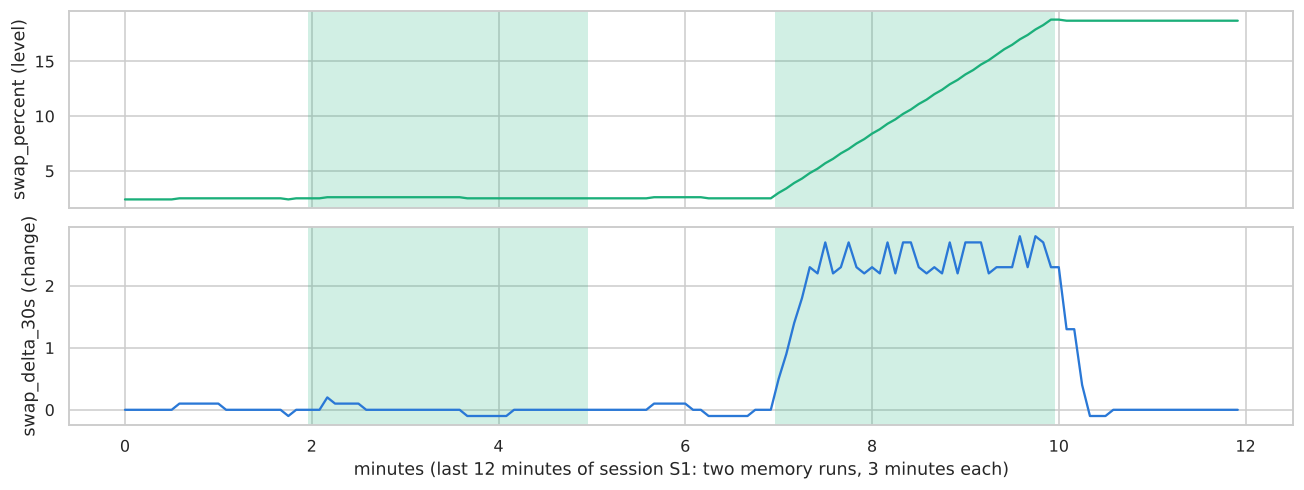

Swap level at the end of S1: 18.7 % (before the memory runs: 2.4 %); swap_delta_30s at the end: 0.00


In [45]:
# Operation 9: swap stays occupied after memory pressure ends, so its level would flag healthy samples;
# its change over 30 s marks the pressure itself. Session S1, the two memory runs
s1_mem = sysd["session_id"].eq("S1") & (
    sysd["ts"]
    >= runs.loc[(runs["session_id"] == "S1") & (runs["label"] == "memory"), "started_at"].min()
    - pd.Timedelta(minutes=2)
)
t = (sysd.loc[s1_mem, "ts"] - sysd.loc[s1_mem, "ts"].min()).dt.total_seconds() / 60
fig, axes = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
axes[0].plot(t, sysd.loc[s1_mem, "swap_percent"], color="#1baf7a")
axes[0].set_ylabel("swap_percent (level)")
axes[1].plot(t, feat.loc[s1_mem, "swap_delta_30s"], color="#2a78d6")
axes[1].set_ylabel("swap_delta_30s (change)")
axes[1].set_xlabel("minutes (last 12 minutes of session S1: two memory runs, 3 minutes each)")
for ax in axes:
    for r in runs[(runs["session_id"] == "S1") & (runs["label"] == "memory")].itertuples():
        origin = sysd.loc[s1_mem, "ts"].min()
        ax.axvspan(
            (r.started_at - origin).total_seconds() / 60,
            (r.ended_at - origin).total_seconds() / 60,
            color=LABEL_COLORS["memory"],
            alpha=0.2,
            linewidth=0,
        )
save("step8_swap_delta")
swap_after = sysd.loc[s1_mem, "swap_percent"].iloc[-1]
swap_before = sysd.loc[s1_mem, "swap_percent"].iloc[0]
delta_after = feat.loc[s1_mem, "swap_delta_30s"].iloc[-1]
print(
    f"Swap level at the end of S1: {swap_after:.1f} % (before the memory runs: {swap_before:.1f} %); "
    f"swap_delta_30s at the end: {delta_after:.2f}"
)

**Observations:** The eleven features are built by one function (5622 rows, no missing values). Around the start of the heavy CPU run of S1 the raw `cpu_percent` jumps from 6.2 at 10:34:57 to 24.6 and then 74.9, while `cpu_roll_mean_30s` follows with a delay (10.1, then 19.4) and reaches 95.6 only at 10:35:37. The rolling standard deviation peaks at 43.8 during the change and falls back to 0.6 once the load is steady, so it signals a change, not a level.

The swap plots show why `swap_delta_30s` replaces `swap_percent`: during the memory runs of S1 the swap level climbs from 2.4 % to 18.7 % and stays there after the run, so a level feature would call every later healthy sample abnormal. The 30 s change rises to as much as 2.8 in the memory runs and is back at 0.00 afterwards.

### 8.1 Further candidate features
Six more columns are constructed as candidates; Step 9 ranks them against the eleven above:

* `cpu_delta_5s` - change of CPU since the previous sample (0 after a gap),
* `load_cpu_gap` - cores the CPU is busy with minus the load average (work done against work queued),
* `log_disk_total_rate`, `log_network_total_rate` - read plus write, sent plus received, on the log scale,
* `hour_sin`, `hour_cos` - cyclic encoding of the time of day (23:59 and 00:00 are close).

In [46]:
extra = pd.DataFrame(index=sysd.index)
step_s = sysd["ts"].diff().dt.total_seconds()
extra["cpu_delta_5s"] = sysd["cpu_percent"].diff().where(step_s <= 7.5, 0.0).fillna(0.0)
extra["load_cpu_gap"] = sysd["cpu_percent"] / 100 * sysd["cpu_count"] - sysd["load_average"]
extra["log_disk_total_rate"] = np.log1p(sysd["disk_read_rate"] + sysd["disk_write_rate"])
extra["log_network_total_rate"] = np.log1p(sysd["network_sent_rate"] + sysd["network_recv_rate"])
minute_of_day = sysd["ts"].dt.hour * 60 + sysd["ts"].dt.minute
extra["hour_sin"] = np.sin(2 * np.pi * minute_of_day / 1440)
extra["hour_cos"] = np.cos(2 * np.pi * minute_of_day / 1440)
with pd.option_context("display.float_format", "{:.4g}".format):
    print(extra.loc[sysd["scored"]].agg(["mean", "std", "min", "max"]).T.to_string())

                            mean    std     min    max
cpu_delta_5s           -0.006032  3.792   -28.9   48.7
load_cpu_gap             0.05464 0.7319    -3.2  4.274
log_disk_total_rate        13.75  2.324   8.425   20.4
log_network_total_rate     11.87  1.857   7.396  17.17
hour_sin                 -0.3571 0.5075 -0.9351    0.5
hour_cos                 -0.5201 0.5871      -1 0.7284


### 8.2 Transformation to reduce skewness
The four rate fields are right-skewed (Step 4). A log transform and a Yeo-Johnson power transform (which also accepts zeros) make the distribution more bell-shaped, so that the rare large values do not dominate distances and split points. Yeo-Johnson learns its exponent from the fit rows only.

Skewness of the rate fields (labelled rows):
                    raw  log1p  Yeo-Johnson
disk_read_rate     4.65   0.70        -0.01
disk_write_rate    4.45   0.97         0.44
network_sent_rate  3.24   0.15         0.10
network_recv_rate  3.33   0.54         0.17


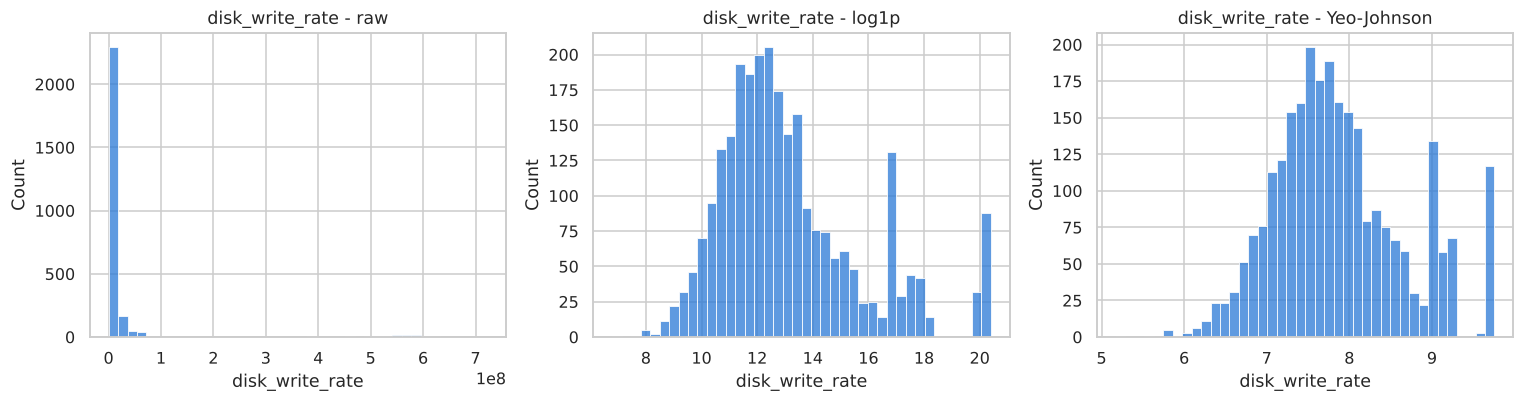

In [47]:
from sklearn.preprocessing import PowerTransformer

power = PowerTransformer(method="yeo-johnson", standardize=False).fit(
    sysd.loc[sysd["is_fit"], RATE_FIELDS]
)
yeo = pd.DataFrame(power.transform(S[RATE_FIELDS]), columns=RATE_FIELDS, index=S.index)
skew_table = pd.DataFrame(
    {"raw": S[RATE_FIELDS].skew(), "log1p": np.log1p(S[RATE_FIELDS]).skew(), "Yeo-Johnson": yeo.skew()}
).round(2)
print("Skewness of the rate fields (labelled rows):")
print(skew_table.to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (title, values) in zip(
    axes,
    [
        ("raw", S["disk_write_rate"]),
        ("log1p", np.log1p(S["disk_write_rate"])),
        ("Yeo-Johnson", yeo["disk_write_rate"]),
    ],
):
    sns.histplot(values, bins=40, color="#2a78d6", ax=ax)
    ax.set_title(f"disk_write_rate - {title}")
save("step8_skew_transforms")

**Observations:** The skewness of the four rate fields falls from 3.24 - 4.65 (raw) to 0.15 - 0.97 with log1p and to between -0.01 and 0.44 with Yeo-Johnson. Both give a distribution that is close to bell shaped for the bulk of ordinary use; the second hump at the right of each histogram is the stress runs. The project uses `log1p`: it needs nothing learned from the data and is easy to repeat exactly in the agent, whereas Yeo-Johnson adds a fitted exponent for every column for a small extra gain in symmetry.

### 8.3 Outlier capping (winsorising)
Capping clips extreme values to a fence instead of deleting the rows. Two rules are shown on `log_disk_write_rate`: the **IQR fence** (Q3 + 1.5 x IQR) and the **99th percentile**, both computed on the fit rows. In anomaly detection the extreme values are the *signal*, so the question is what capping does to the stress runs.

IQR fence: 16.90 | 99th percentile: 17.31 | largest value: 20.40

Share of the labelled rows that capping changes (value at or above the cap), %:
         IQR fence  99th percentile
label                              
normal         0.6              0.2
cpu            0.0              0.0
memory        50.0             40.8
disk          51.2             50.0
network        0.0              0.0


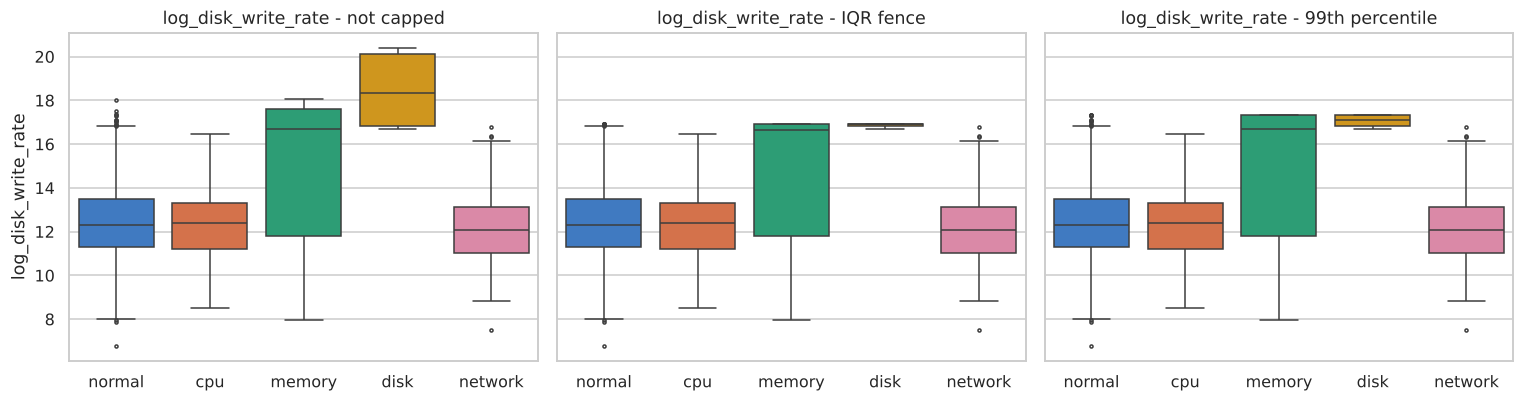

In [48]:
col = "log_disk_write_rate"
fit_values = feat.loc[sysd["is_fit"], col]
q1, q3 = fit_values.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
p99 = fit_values.quantile(0.99)
print(f"IQR fence: {fence:.2f} | 99th percentile: {p99:.2f} | largest value: {feat[col].max():.2f}")

lab_rows = sysd["scored"]
share = pd.DataFrame(
    {
        "IQR fence": (feat.loc[lab_rows, col] >= fence).groupby(sysd.loc[lab_rows, "label"]).mean(),
        "99th percentile": (feat.loc[lab_rows, col] >= p99).groupby(sysd.loc[lab_rows, "label"]).mean(),
    }
)
print("\nShare of the labelled rows that capping changes (value at or above the cap), %:")
print((share.reindex(LABELS) * 100).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (title, values) in zip(
    axes,
    [
        ("not capped", feat[col]),
        ("IQR fence", feat[col].clip(upper=fence)),
        ("99th percentile", feat[col].clip(upper=p99)),
    ],
):
    sns.boxplot(
        x=sysd.loc[lab_rows, "label"],
        y=values[lab_rows],
        hue=sysd.loc[lab_rows, "label"],
        order=LABELS,
        hue_order=LABELS,
        palette=LABEL_COLORS,
        legend=False,
        fliersize=2,
        ax=ax,
    )
    ax.set_title(f"{col} - {title}")
    ax.set_xlabel("")
save("step8_capping")

**Observations:** On `log_disk_write_rate` the IQR fence of ordinary use is 16.90 and the 99th percentile is 17.31, while the largest value is 20.40. Capping at the IQR fence would change 51.2 % of the disk rows and 50.0 % of the memory rows (swapping writes to disk) but only 0.6 % of the normal rows; the 99th percentile would change 50.0 % of the disk rows and 40.8 % of the memory rows. The second and third box plots show what is lost: the disk box shrinks to a thin line and the heavy disk runs can no longer be told from the moderate ones. In anomaly detection the extreme values are the signal, so capping is **not** applied to the final features; it is the right tool when extremes are errors, and Step 2 deals with those by the range check.

### 8.4 Dimensionality reduction with PCA
Principal Component Analysis combines correlated columns into a smaller number of uncorrelated components. Here the eleven features are standardised and PCA is fitted on the **fit rows** (ordinary use); the stress rows are then projected into the same plane. The first two components are kept as candidate features `pc1` and `pc2`.

Explained variance of ordinary use, per component (%): [30.  10.3  9.8  9.2  8.6  8.1]
Cumulative (%): [30.  40.2 50.  59.2 67.8 75.9]


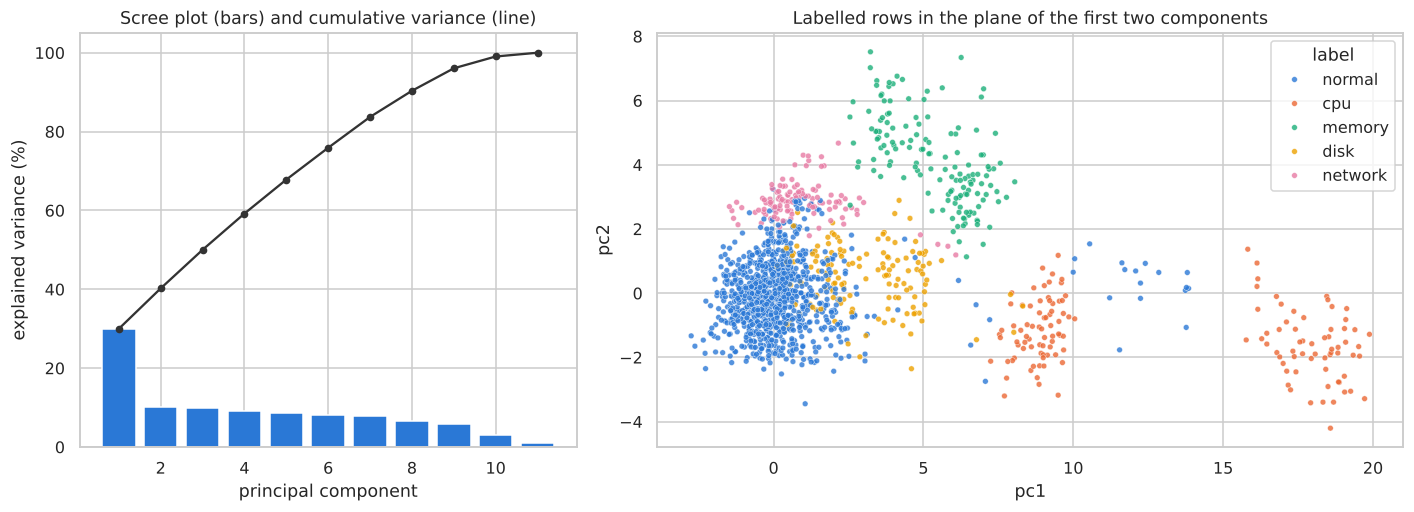

In [49]:
from sklearn.decomposition import PCA

scaler11 = StandardScaler().fit(feat.loc[sysd["is_fit"], FEATURES])
Z = scaler11.transform(feat[FEATURES])  # all rows, scaled with the fit rows' mean and std
pca = PCA(random_state=RANDOM_STATE).fit(Z[sysd["is_fit"].to_numpy()])
ratio = pca.explained_variance_ratio_
print("Explained variance of ordinary use, per component (%):", (ratio * 100).round(1)[:6])
print("Cumulative (%):", (np.cumsum(ratio) * 100).round(1)[:6])
components = pca.transform(Z)
extra["pc1"], extra["pc2"] = components[:, 0], components[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(np.arange(1, len(ratio) + 1), ratio * 100, color="#2a78d6")
axes[0].plot(
    np.arange(1, len(ratio) + 1), np.cumsum(ratio) * 100, color="#333333", marker="o", markersize=4
)
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("explained variance (%)")
axes[0].set_title("Scree plot (bars) and cumulative variance (line)")
shown = sysd.loc[sysd["scored"]].sample(1500, random_state=RANDOM_STATE)
sns.scatterplot(
    x=extra.loc[shown.index, "pc1"],
    y=extra.loc[shown.index, "pc2"],
    hue=shown["label"],
    hue_order=LABELS,
    palette=LABEL_COLORS,
    s=14,
    alpha=0.8,
    ax=axes[1],
)
axes[1].set_title("Labelled rows in the plane of the first two components")
save("step8_pca")

**Observations:** The first component explains 30.0 % of the variance of ordinary use, the first two 40.2 % and the first six 75.9 %. The eleven features are therefore not redundant - ordinary use varies in many directions - and PCA cannot compress them much without losing information. In the plane of the first two components the normal rows form one compact cloud around the origin, while every stress type is pushed out in its own direction: cpu rows far to the right (PC1 up to about 20), memory rows upwards, network rows to the upper left and disk rows in between. That is what an anomaly detector exploits: stress is a displacement from the cloud of ordinary use, in a different direction for each type. `pc1` and `pc2` stay candidates for Step 9; their drawback is that a component is a blend of all eleven features and cannot be explained to an operator as "CPU" or "disk".

### 8.5 Operating-mode feature with K-Means clustering
K-Means groups the rows by what the machine is doing. It is fitted on the fit rows only and **without labels**, so the clusters describe ordinary operating modes; the stress rows are assigned to the nearest mode. The cluster number becomes a categorical feature `kmeans_mode` and the distance to the nearest centre a continuous one, `kmeans_distance`. The number of clusters is chosen with the silhouette score.

Silhouette score by number of clusters: {2: 0.657, 3: 0.122, 4: 0.105, 5: 0.123, 6: 0.109, 7: 0.101, 8: 0.105}
Chosen k: 2

Operating modes found in ordinary use (fit rows):
      rows  mean_cpu  mean_ram
mode                          
0     2766      10.6      47.1
1       59      46.4      51.7

Share of each label in the modes (%):
kmeans_mode   0    1
label               
normal       97    3
cpu           0  100
memory       26   74
disk         85   15
network      97    3


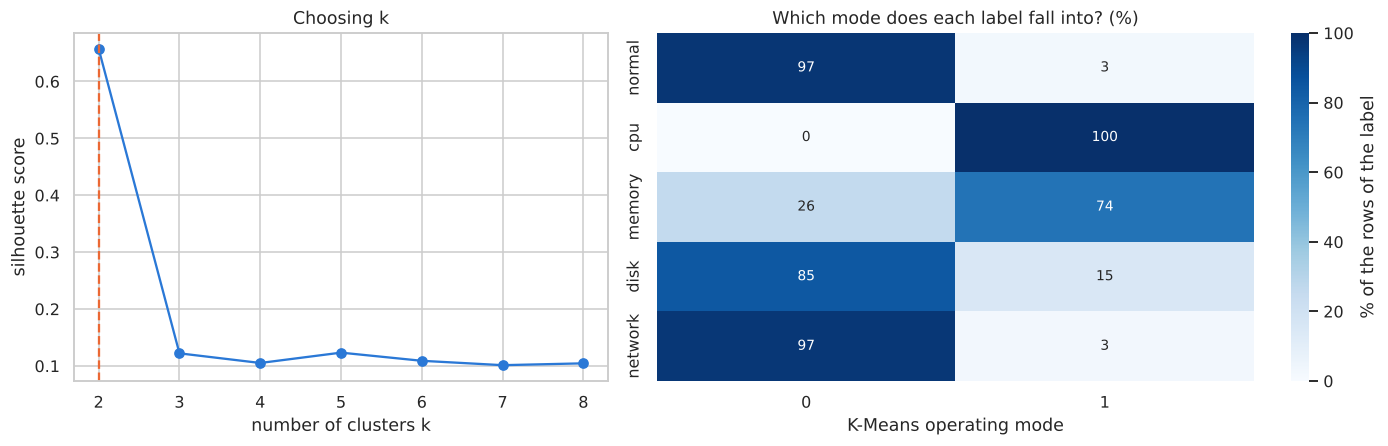

In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Z_fit = Z[sysd["is_fit"].to_numpy()]
silhouette = {
    k: silhouette_score(
        Z_fit, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_fit)
    )
    for k in range(2, 9)
}
best_k = max(silhouette, key=silhouette.get)
print("Silhouette score by number of clusters:", {k: round(float(v), 3) for k, v in silhouette.items()})
print("Chosen k:", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Z_fit)
extra["kmeans_mode"] = kmeans.predict(Z)
extra["kmeans_distance"] = kmeans.transform(Z).min(axis=1)

share = (
    pd.crosstab(
        sysd.loc[lab_rows, "label"], extra.loc[lab_rows, "kmeans_mode"], normalize="index"
    ).reindex(LABELS)
    * 100
)

modes = sysd.loc[sysd["is_fit"], ["cpu_percent", "ram_percent"]].assign(mode=kmeans.labels_)
print("\nOperating modes found in ordinary use (fit rows):")
print(
    modes.groupby("mode")
    .agg(rows=("mode", "size"), mean_cpu=("cpu_percent", "mean"), mean_ram=("ram_percent", "mean"))
    .round(1)
    .to_string()
)
print("\nShare of each label in the modes (%):")
print(share.round(0).astype(int).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(list(silhouette), list(silhouette.values()), marker="o", color="#2a78d6")
axes[0].axvline(best_k, color="#eb6834", linestyle="--")
axes[0].set_xlabel("number of clusters k")
axes[0].set_ylabel("silhouette score")
axes[0].set_title("Choosing k")
sns.heatmap(
    share,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    annot_kws={"size": 9},
    ax=axes[1],
    cbar_kws={"label": "% of the rows of the label"},
)
axes[1].set_xlabel("K-Means operating mode")
axes[1].set_ylabel("")
axes[1].set_title("Which mode does each label fall into? (%)")
save("step8_kmeans")

**Observations:** The silhouette score is clearly highest for two clusters (0.657, against 0.122 for three), so ordinary use has two operating modes: a quiet mode of 2766 rows (mean CPU 10.6 %, RAM 47.1 %) and a small busy mode of 59 rows (CPU 46.4 %, RAM 51.7 %) that holds the short busy episodes of ordinary use. The stress rows are assigned to whichever mode is nearer: all cpu rows (100 %) fall into the busy mode, and so do 74 % of the memory rows, while 97 % of the network rows and 85 % of the disk rows look like the quiet mode. The mode number alone therefore cannot name a stress type; the useful part is `kmeans_distance`, the distance to the nearest centre, which grows when a row is far from both ordinary modes.

## Step 9 - Feature selection

Not every engineered column is useful. Two filter methods rank the candidates against the target `is_stress`: the **chi-square test** (for non-negative features, so they are scaled to 0-1 first) and **mutual information** (any feature, also non-linear). Near-constant columns and pairs of near-duplicate columns are identified as well.

The ranking uses the **labelled rows of sessions S1 to S4 only**: the test session S5 is opened once, at the end. The candidates come in six groups: the eleven project features, four extra constructed features, the time of day, the PCA and K-Means columns, the encoded process-table columns, and two constant columns that are included on purpose to show that the filters find them. A high score is not enough - the ranking has to be read together with *how the data was collected*, because the stress runs follow a fixed protocol.

In [51]:
from sklearn.feature_selection import mutual_info_classif, chi2, VarianceThreshold

extra_cols = ["cpu_delta_5s", "load_cpu_gap", "log_disk_total_rate", "log_network_total_rate"]
GROUPS = {
    "project features (11)": FEATURES,
    "extra constructed": extra_cols,
    "time of day": ["hour_sin", "hour_cos"],
    "PCA and K-Means": ["pc1", "pc2", "kmeans_mode", "kmeans_distance"],
    "process-table codes": list(status_cols.columns)
    + list(process_bits.columns)
    + ["top_io_process_freq"],
    "constant columns": ["cpu_count", "ram_total"],
}
group_of = {col: group for group, cols in GROUPS.items() for col in cols}

candidates = pd.concat(
    [feat, extra, enc[GROUPS["process-table codes"]], sysd[GROUPS["constant columns"]]], axis=1
)
candidates = candidates[list(group_of)]
rank_rows = sysd["scored"] & (sysd["session_id"] != "S5")
X_rank, y_rank = candidates[rank_rows], enc.loc[rank_rows, "is_stress"]
print(
    "Candidate columns:",
    candidates.shape[1],
    "| rows used for the ranking:",
    len(X_rank),
    f"(stress share {y_rank.mean() * 100:.1f} %)",
)

mi = mutual_info_classif(X_rank, y_rank, random_state=RANDOM_STATE)
chi, _ = chi2(MinMaxScaler().fit_transform(X_rank), y_rank)
ranking = pd.DataFrame(
    {
        "feature": candidates.columns,
        "group": [group_of[c] for c in candidates.columns],
        "MI": mi,
        "chi2": np.nan_to_num(chi),
    }
)
ranking["rank_MI"] = ranking["MI"].rank(ascending=False, method="min").astype(int)
ranking["rank_chi2"] = ranking["chi2"].rank(ascending=False, method="min").astype(int)
ranking = ranking.sort_values("MI", ascending=False).reset_index(drop=True)
print(ranking.head(18).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Candidate columns: 34 | rows used for the ranking: 2131 (stress share 34.9 %)
            feature                 group    MI    chi2  rank_MI  rank_chi2
           hour_sin           time of day 0.640   3.160        1         24
           hour_cos           time of day 0.618   2.041        2         25
    kmeans_distance       PCA and K-Means 0.453 169.939        3          5
                pc1       PCA and K-Means 0.337 144.710        4          6
      load_per_core project features (11) 0.336 134.699        5          8
  cpu_roll_mean_30s project features (11) 0.257 117.107        6         10
        cpu_percent project features (11) 0.249 117.454        7          9
        ram_percent project features (11) 0.242 137.476        8          7
    status_sleeping   process-table codes 0.204 304.087        9          4
                pc2       PCA and K-Means 0.189  19.894       10         15
        kmeans_mode       PCA and K-Means 0.185 644.797       11          1
log_disk_t

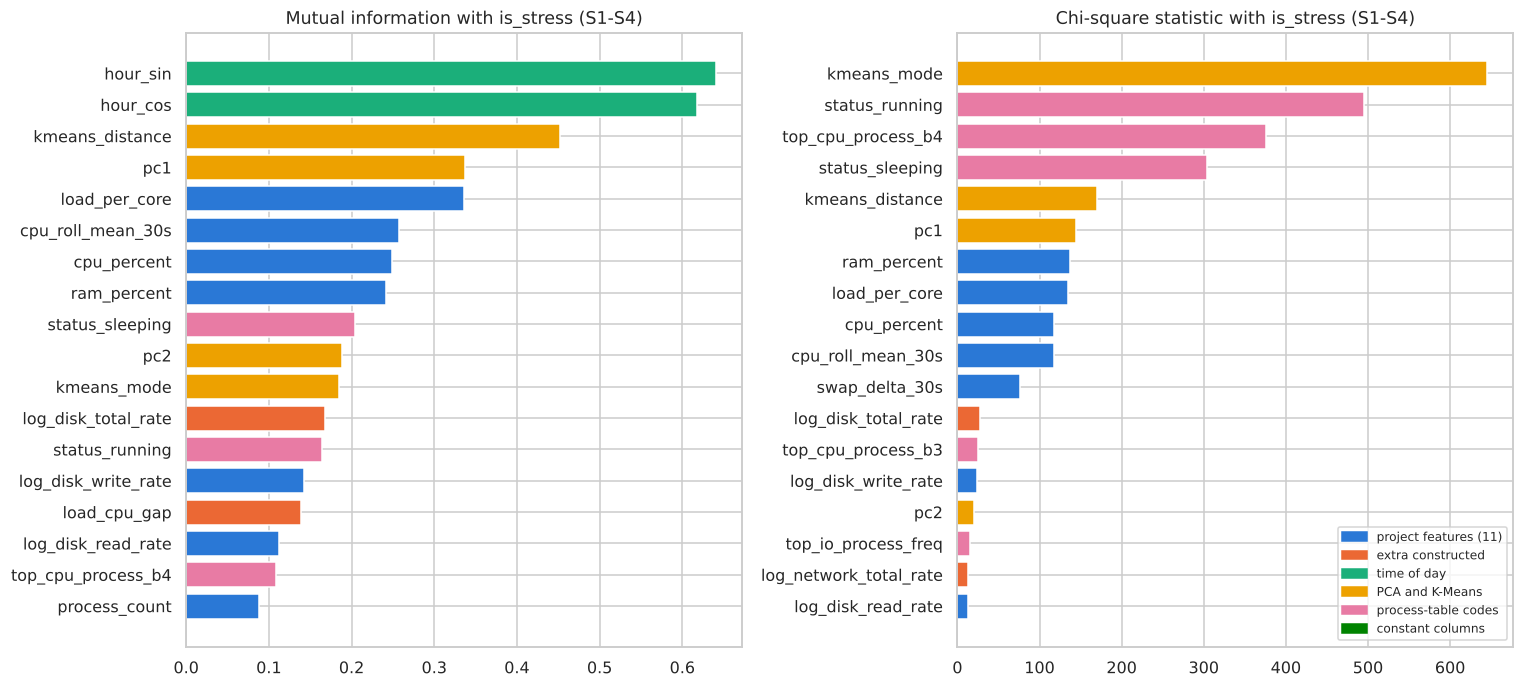

In [52]:
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, col, title in zip(axes, ["MI", "chi2"], ["Mutual information", "Chi-square statistic"]):
    top = ranking.sort_values(col, ascending=False).head(18).iloc[::-1]
    ax.barh(top["feature"], top[col], color=[GROUP_COLORS[g] for g in top["group"]])
    ax.set_title(title + " with is_stress (S1-S4)")
axes[1].legend(
    [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()],
    list(GROUP_COLORS),
    loc="lower right",
    fontsize=8,
)
save("step9_ranking")

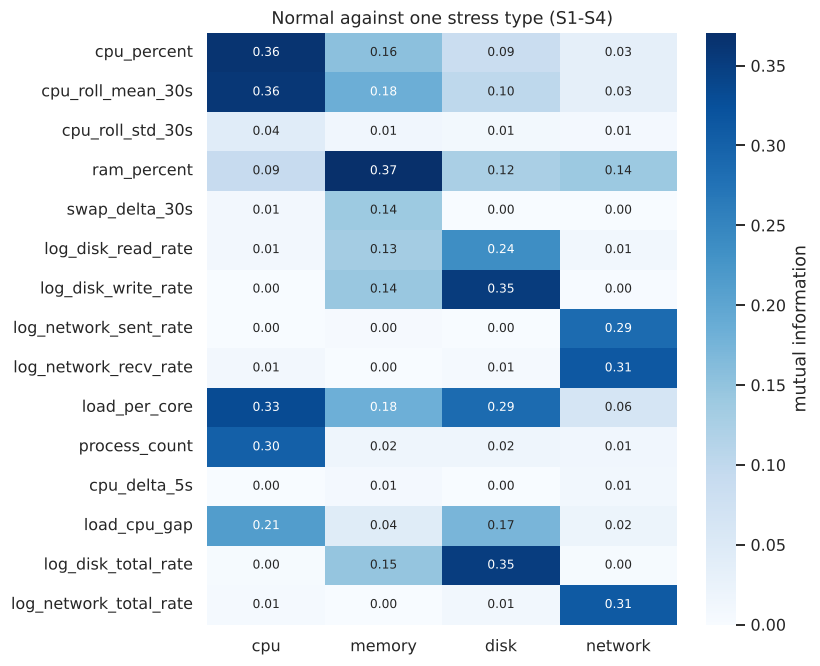

Strongest feature for each stress type:
  cpu      cpu_percent            MI = 0.36
  memory   ram_percent            MI = 0.37
  disk     log_disk_write_rate    MI = 0.35
  network  log_network_recv_rate  MI = 0.31


In [53]:
# Which feature identifies which stress type? Mutual information of normal against one type at a time
type_cols = FEATURES + extra_cols
type_mi = {}
for kind in ["cpu", "memory", "disk", "network"]:
    rows = rank_rows & sysd["label"].isin(["normal", kind])
    type_mi[kind] = mutual_info_classif(
        candidates.loc[rows, type_cols],
        (sysd.loc[rows, "label"] == kind).astype(int),
        random_state=RANDOM_STATE,
    )
type_mi = pd.DataFrame(type_mi, index=type_cols)
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(
    type_mi,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    annot_kws={"size": 8},
    ax=ax,
    cbar_kws={"label": "mutual information"},
)
ax.set_title("Normal against one stress type (S1-S4)")
save("step9_mi_by_type")
print("Strongest feature for each stress type:")
for kind, feature in type_mi.idxmax().items():
    print(f"  {kind:8s} {feature:22s} MI = {type_mi.loc[feature, kind]:.2f}")

In [54]:
# Near-constant columns (variance of the 0-1 scaled column < 0.001) and near-duplicate pairs (|r| > 0.95)
scaled_rank = pd.DataFrame(MinMaxScaler().fit_transform(X_rank), columns=X_rank.columns)
low_variance = [c for c, v in scaled_rank.var().items() if v < 0.001]
print("Variance below 0.001:", ", ".join(low_variance))
selector = VarianceThreshold(threshold=0.001).fit(scaled_rank)
print(
    "VarianceThreshold keeps", int(selector.get_support().sum()), "of", scaled_rank.shape[1], "columns"
)

corr = candidates.loc[rank_rows, FEATURES + extra_cols].corr().abs()
pairs = [
    (a, b, corr.loc[a, b])
    for i, a in enumerate(corr.columns)
    for b in corr.columns[i + 1 :]
    if corr.loc[a, b] > 0.95
]
print("\nPairs with |r| > 0.95:")
for a, b, r in sorted(pairs, key=lambda p: -p[2]):
    print(f"  {a:24s} {b:24s} r = {r:.3f}")

Variance below 0.001: cpu_count, ram_total
VarianceThreshold keeps 32 of 34 columns

Pairs with |r| > 0.95:
  cpu_percent              cpu_roll_mean_30s        r = 0.977


In [55]:
# Leakage check 1: the process-table codes name the stress tool itself (stress-ng, fio, curl)
leaky = ["process-table codes", "time of day"]
print("Best-ranked process-table columns:")
print(
    ranking[ranking["group"] == "process-table codes"]
    .head(4)[["feature", "MI", "rank_MI"]]
    .to_string(index=False, float_format=lambda v: f"{v:.3f}")
)

# Leakage check 2: every session starts with half an hour of ordinary use, so the clock time
# marks the phase of the protocol
phase = sysd.loc[rank_rows, ["session_id", "ts"]].assign(
    use=y_rank.map({0: "normal rows", 1: "stress rows"})
)
span = phase.groupby(["session_id", "use"])["ts"].agg(["min", "max"])
print("\nClock time (UTC) covered by the labelled rows of each session:")
print(
    (span["min"].dt.strftime("%H:%M") + " - " + span["max"].dt.strftime("%H:%M")).unstack().to_string()
)

# Do the two suspicious groups still work in a session that was not used for training? S5 stays closed:
# a Random Forest is trained on S1-S3 and scored on S4.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

train_rows, held_rows = rank_rows & sysd["session_id"].isin(["S1", "S2", "S3"]), rank_rows & (
    sysd["session_id"] == "S4"
)
print("\nROC-AUC on session S4 of a Random Forest trained on S1-S3:")
for name, cols in {
    "clock time (2 columns)": GROUPS["time of day"],
    "process-table codes": GROUPS["process-table codes"],
    "the 11 project features": FEATURES,
}.items():
    forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
    forest.fit(candidates.loc[train_rows, cols], enc.loc[train_rows, "is_stress"])
    auc = roc_auc_score(
        enc.loc[held_rows, "is_stress"], forest.predict_proba(candidates.loc[held_rows, cols])[:, 1]
    )
    print(f"  {name:26s} {auc:.3f}")

# Where do the eleven project features rank among the legitimate candidates?
legit = ranking[~ranking["group"].isin(leaky + ["constant columns"])].reset_index(drop=True)
legit["rank_legit"] = legit.index + 1
spec_ranks = legit[legit["group"] == "project features (11)"][["feature", "MI", "chi2", "rank_legit"]]
print(f"\nThe 11 project features among the {len(legit)} legitimate candidates:")
print(spec_ranks.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Best-ranked process-table columns:
            feature    MI  rank_MI
    status_sleeping 0.204        9
     status_running 0.164       13
 top_cpu_process_b4 0.108       17
top_io_process_freq 0.086       19

Clock time (UTC) covered by the labelled rows of each session:
use           normal rows    stress rows
session_id                              
S1          10:00 - 10:29  10:30 - 11:07
S2          15:30 - 15:59  16:00 - 16:37
S3          11:15 - 11:44  11:45 - 12:22
S4          20:00 - 20:29  20:30 - 21:07

ROC-AUC on session S4 of a Random Forest trained on S1-S3:
  clock time (2 columns)     0.491
  process-table codes        0.961
  the 11 project features    1.000

The 11 project features among the 19 legitimate candidates:
              feature    MI    chi2  rank_legit
        load_per_core 0.336 134.699           3
    cpu_roll_mean_30s 0.257 117.107           4
          cpu_percent 0.249 117.454           5
          ram_percent 0.242 137.476           6
  log_disk_wri

**Observations:**

* **The clock columns win the ranking and are worthless.** `hour_sin` and `hour_cos` have the highest mutual information (0.640 and 0.618), but every session starts with half an hour of ordinary use (S1: normal rows 10:00 - 10:29, stress rows 10:30 - 11:07), so the time of day only says where in the protocol a row lies. A Random Forest trained on the two clock columns of S1-S3 scores a ROC-AUC of 0.491 on S4, no better than guessing, whereas the eleven project features reach 1.000.
* **The process-table codes transfer, but they cheat.** They reach 0.961 on S4 because the process names reveal the stress tool (Step 5); a runaway process with another name would not be recognised. Both groups are excluded from the candidates.
* **Among the 19 legitimate candidates** the strongest are `kmeans_distance` and `pc1` (functions of the eleven features), then `load_per_core` (0.336), `cpu_roll_mean_30s` (0.257), `cpu_percent` (0.249) and `ram_percent` (0.242); the chi-square test agrees, with these four columns in its top ten. The weakest project feature is `cpu_roll_std_30s` (MI 0.000): it is large only in the 30 seconds after a run starts or stops, not during the steady 3 minutes, so a filter that judges one column at a time cannot value it. It stays because the specification includes it as the signal of sudden changes, and the full model comparison will show whether the detectors use it.
* **Redundant and constant columns.** `cpu_percent` and `cpu_roll_mean_30s` are near duplicates (r = 0.977); both are kept, because the rolling mean smooths single-sample noise. `cpu_count` and `ram_total` have a variance below 0.001 and are removed by `VarianceThreshold`.
* **Decision.** The final set is the eleven features of the specification. The four PCA and K-Means columns and the four extra columns are functions of the same measurements (a component, a distance, a sum, a difference) and add no new information, and a small fixed set means that the agent can compute exactly the same features at run time.

## Step 10 - The final feature-engineered dataset

In [56]:
# The labelled rows (for scoring) and the ordinary-use rows (for fitting), with the 11 project features
final = pd.concat(
    [sysd[["session_id", "ts", "label", "intensity", "is_fit", "scored"]], feat[FEATURES]], axis=1
)
final.insert(4, "is_stress", enc["is_stress"])
final = final[final["is_fit"] | final["scored"]].reset_index(drop=True)
final["ts"] = final["ts"].dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ").str[:-4] + "Z"
final.to_csv("Kali_Feature_Engineered.csv", index=False)

readable = sysd.loc[
    sysd["is_fit"] | sysd["scored"],
    [
        "session_id",
        "ts",
        "label",
        "intensity",
        "cpu_percent",
        "ram_percent",
        "swap_percent",
        "disk_read_rate",
        "disk_write_rate",
        "network_sent_rate",
        "network_recv_rate",
        "load_average",
        "process_count",
        "top_cpu_process",
        "top_cpu_status",
    ],
]
readable.to_csv("Kali_Cleaned_Readable.csv", index=False)

print("Kali_Feature_Engineered.csv:", final.shape, "| Kali_Cleaned_Readable.csv:", readable.shape)
print(
    "Missing values in the 11 features:",
    int(final[FEATURES].isna().sum().sum()),
    "| non-numerical feature columns:",
    int((~final[FEATURES].dtypes.map(pd.api.types.is_numeric_dtype)).sum()),
)
print("\nRows per session and use (fit = ordinary use for fitting, scored = labelled rows):")
print(
    pd.DataFrame(
        {
            "fit": final.groupby("session_id")["is_fit"].sum(),
            "scored": final.groupby("session_id")["scored"].sum(),
        }
    ).to_string()
)
final.head(4)

Kali_Feature_Engineered.csv: (4107, 18) | Kali_Cleaned_Readable.csv: (4107, 15)
Missing values in the 11 features: 0 | non-numerical feature columns: 0

Rows per session and use (fit = ordinary use for fitting, scored = labelled rows):
             fit  scored
session_id              
BG          1438       0
S1           348     540
S2           344     536
S3           347     515
S4           348     540
S5             0     538


,session_id,ts,label,intensity,is_stress,is_fit,scored,cpu_percent,cpu_roll_mean_30s,cpu_roll_std_30s,ram_percent,swap_delta_30s,log_disk_read_rate,log_disk_write_rate,log_network_sent_rate,log_network_recv_rate,load_per_core,process_count
0,BG,2026-01-05T07:30:07.479Z,background,none,0,True,False,9.4,9.400000,0.000000,44.9,0.0,11.734837,13.204099,8.182392,9.687276,0.09250,299
1,BG,2026-01-05T07:30:12.515Z,background,none,0,True,False,6.7,8.050000,1.909188,44.9,0.0,10.533873,12.837469,8.430763,8.562415,0.09250,299
2,BG,2026-01-05T07:30:17.519Z,background,none,0,True,False,5.7,7.266667,1.913984,44.9,0.0,11.271668,12.055287,9.386669,8.988758,0.09125,300
3,BG,2026-01-05T07:30:22.461Z,background,none,0,True,False,5.1,6.725000,1.901534,44.8,0.0,9.116370,10.201842,7.778002,9.765242,0.08625,300


### 10.1 Sanity check - does the engineered data work in a model?
Three quick checks confirm that the dataset is usable. None of them is the aim of this assignment; the full comparison with cross-validation and tuning is the next stage of the project.

* **Ceiling check (labels used).** A Random Forest is trained on the labelled rows of S1-S4 and tested on S5. It shows how much of the stress is visible in the eleven features at all.
* **Isolation Forest (no labels).** It is fitted on the ordinary-use rows only and flags a sample whose score is above the 99th percentile of the training scores.
* **Percentile rule (no labels).** The plain baseline of the project: flag a sample when any feature is above its 99th percentile in the ordinary-use rows.

In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score,
    roc_curve,
)

train = final[final["scored"] & (final["session_id"] != "S5")]
test = final[final["scored"] & (final["session_id"] == "S5")]
fit_rows = final[final["is_fit"] & (final["session_id"] != "S5")]
y_true = test["is_stress"].to_numpy()
print(
    f"train (labelled, S1-S4): {len(train)} rows | fit (ordinary use): {len(fit_rows)} rows "
    f"| test (S5): {len(test)} rows"
)
print(f"A detector that never alarms is right on {(1 - y_true.mean()) * 100:.1f} % of the test rows.\n")

# 1. Ceiling check - supervised
forest = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
forest.fit(train[FEATURES], train["is_stress"])
forest_score = forest.predict_proba(test[FEATURES])[:, 1]
# 2. Isolation Forest - fitted on ordinary use, threshold = 99th percentile of the training scores
iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE).fit(fit_rows[FEATURES])
threshold = np.percentile(-iso.score_samples(fit_rows[FEATURES]), 99)
iso_score = -iso.score_samples(test[FEATURES])
# 3. Percentile rule - the score is the largest distance above a median in units of (p99 - median)
median, limit = fit_rows[FEATURES].median(), fit_rows[FEATURES].quantile(0.99)
rule_score = ((test[FEATURES] - median) / (limit - median).clip(lower=1e-9)).max(axis=1).to_numpy()

detectors = {
    "Random Forest (labels used)": (forest_score, forest_score >= 0.5),
    "Isolation Forest (no labels)": (iso_score, iso_score > threshold),
    "Percentile rule (no labels)": (rule_score, rule_score > 1),
}
rows = []
for name, (score, flagged) in detectors.items():
    p, r, f, _ = precision_recall_fscore_support(y_true, flagged, average="binary", zero_division=0)
    rows.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_true, flagged),
            "precision": p,
            "recall": r,
            "F1": f,
            "ROC-AUC": roc_auc_score(y_true, score),
            "avg precision": average_precision_score(y_true, score),
        }
    )
results = pd.DataFrame(rows).set_index("model")
print(results.round(3).to_string())

train (labelled, S1-S4): 2131 rows | fit (ordinary use): 2825 rows | test (S5): 538 rows
A detector that never alarms is right on 64.3 % of the test rows.

                              accuracy  precision  recall     F1  ROC-AUC  avg precision
model                                                                                   
Random Forest (labels used)      0.993      0.980   1.000  0.990    0.999          0.997
Isolation Forest (no labels)     0.654      0.558   0.151  0.238    0.890          0.689
Percentile rule (no labels)      0.849      0.810   0.755  0.782    0.908          0.838


Share of the stress rows of S5 that each detector flags (%):
                   Isolation Forest  Percentile rule
label   intensity                                   
cpu     moderate                  4               96
        heavy                   100              100
memory  moderate                  0              100
        heavy                    17              100
disk    moderate                  0                4
        heavy                     0              100
network moderate                  0                4
        heavy                     0              100

False alarms on the normal rows of S5: Isolation Forest 6.6 %, percentile rule 9.8 %


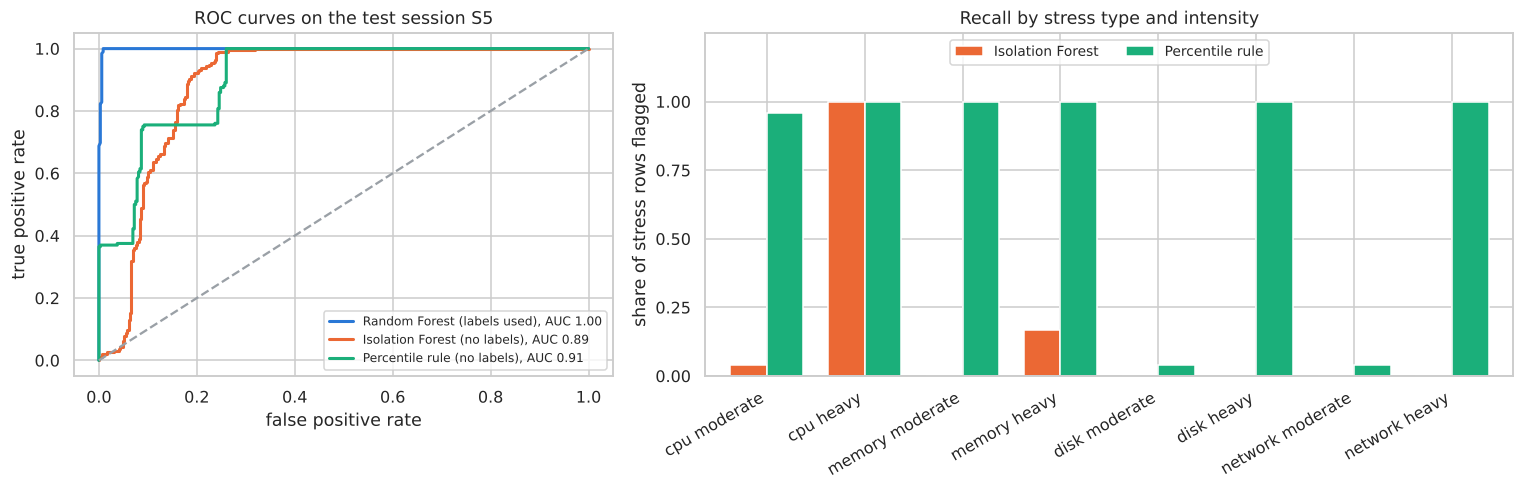

In [58]:
# Recall of the two detectors without labels for each stress type and intensity, and their false alarms
flags = test.assign(isolation=(iso_score > threshold).astype(int), rule=(rule_score > 1).astype(int))
stress = flags[flags["is_stress"] == 1]
recall = (
    stress.groupby(["label", "intensity"])[["isolation", "rule"]]
    .mean()
    .rename(columns={"isolation": "Isolation Forest", "rule": "Percentile rule"})
)
recall = recall.reindex(
    [(l, i) for l in ["cpu", "memory", "disk", "network"] for i in ["moderate", "heavy"]]
)
print("Share of the stress rows of S5 that each detector flags (%):")
print((recall * 100).round(0).astype(int).to_string())
normal = flags[flags["is_stress"] == 0]
print(
    "\nFalse alarms on the normal rows of S5:",
    f"Isolation Forest {normal['isolation'].mean() * 100:.1f} %,",
    f"percentile rule {normal['rule'].mean() * 100:.1f} %",
)

DETECTOR_COLORS = {
    "Random Forest (labels used)": "#2a78d6",
    "Isolation Forest (no labels)": "#eb6834",
    "Percentile rule (no labels)": "#1baf7a",
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
for name, (score, _) in detectors.items():
    fpr, tpr, _ = roc_curve(y_true, score)
    axes[0].plot(
        fpr,
        tpr,
        color=DETECTOR_COLORS[name],
        linewidth=2,
        label=f"{name}, AUC {roc_auc_score(y_true, score):.2f}",
    )
axes[0].plot([0, 1], [0, 1], color="#9aa0a6", linestyle="--")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves on the test session S5")
axes[0].legend(loc="lower right", fontsize=8)
recall.plot(
    kind="bar",
    ax=axes[1],
    color=[
        DETECTOR_COLORS["Isolation Forest (no labels)"],
        DETECTOR_COLORS["Percentile rule (no labels)"],
    ],
    width=0.75,
)
axes[1].set_xticklabels([f"{l} {i}" for l, i in recall.index], rotation=30, ha="right")
axes[1].set_ylim(0, 1.25)
axes[1].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[1].legend(loc="upper center", ncol=2, fontsize=9)
axes[1].set_xlabel("")
axes[1].set_ylabel("share of stress rows flagged")
axes[1].set_title("Recall by stress type and intensity")
save("step10_sanity_check")

**Observations:** The final file has 4107 rows and no missing value: the labelled rows of the five sessions plus the ordinary-use rows used for fitting. The ceiling check shows how much of the stress the eleven features expose: a Random Forest trained with labels on S1-S4 scores an accuracy of 0.993 and a ROC-AUC of 0.999 on the unseen session S5, so the information is there.

Without labels, the Isolation Forest ranks the rows well (ROC-AUC 0.890), but its alarm threshold, the 99th percentile of the training scores, is strict: it flags only 15.1 % of the stress rows (precision 0.558, F1 0.238), and its accuracy of 0.654 is hardly above the 64.3 % of a detector that never alarms. The percentile rule does better on this recording (recall 0.755, precision 0.810, F1 0.782, accuracy 0.849, ROC-AUC 0.908), at 9.8 % false alarms against 6.6 %. By type, the Isolation Forest finds all heavy cpu rows and few others, while the percentile rule finds every heavy run and the moderate cpu and memory runs but misses the moderate disk and network runs (4 % each).

These numbers are a first look on the demonstration recording, not the result of the project: threshold tuning, cross-validation on S1-S4 and the comparison with LOF belong to the next stage.

## Conclusion

* **Result.** The raw monitoring recording (5636 system rows x 19 columns, 49976 process rows and 85 labelled runs) was transformed into a clean, fully numerical table of 4107 rows with the eleven features of the project, no missing values and the masks that separate the fitting rows from the test session.
* **Cleaning** repaired 30 late rows, 6 repeated rows and 3 impossible values, folded 32 process names into 29 and labelled 2672 samples from the run table, trimming the edges of every run and voiding the one run that lost samples.
* **Missing values** were handled by cause: rate fields dropped (they cannot be known), denied I/O counters filled with 0 plus an indicator, an unknown status as a new category, thread counts by the median. An experiment on hidden values showed linear interpolation beating the mean and the median by a wide margin on time-ordered columns.
* **Visualisation** showed that each stress type is carried by its own field (CPU, RAM, disk write, network receive), that 64.9 % of the labelled rows are normal, that the same protocol repeats in all five sessions, and that the process names reveal the stress tool.
* **Encoding** used label, ordinal, one-hot, binary and frequency encoding, each matched to the number and order of the categories; the process-derived columns were kept for demonstration and for the leakage check only.
* **Scaling** compared four scalers: `StandardScaler`, fitted on ordinary use, is needed only by LOF (ROC-AUC 0.709 to 0.833), while the Isolation Forest is unaffected (0.915 both ways).
* **New features** - the eleven features (log1p of the four rates, load per core, 30 s rolling mean and standard deviation of the CPU, 30 s change of swap) were built by one function, next to candidates such as cyclic time, PCA components and the K-Means distance; capping was rejected because it flattens the signal of the stress runs.
* **Feature selection** with mutual information and chi-square, plus a test on a session that was not used for training, showed that the clock columns (ROC-AUC 0.491 on a new session) and the process-table codes are leaks; the eleven specified features were kept (ROC-AUC 1.000 on S4).
* **Sanity check** on the unseen session S5: ROC-AUC 0.999 for a Random Forest with labels, and 0.890 for the Isolation Forest and 0.908 for the percentile rule without labels, which leaves the choice of the alarm threshold to the model stage.
* **Limitation:** the recording is a generated demonstration recording in the schema of the agent, so these numbers describe it and not a measured laptop. The notebook runs unchanged on the agent's own `system.csv`, `process.csv` and `experiments.csv`; the sentences above must then be re-read against the new outputs.